# PCA of attack bouts, with watershed clusters

Step 4g of the pipeline (see `README.md`). How do the groups' attack bouts occupy feature space? `FEATURES` in the settings picks what the PCA runs on:

- `"summary"`: the 13 summary features (position, speed, facing, who is approaching).
- `"path"`: the approach path itself, 60 frames × (x, y). Each component is then a path shape, drawn below.
- `"kinematics"`: heading and movement of both mice over the 2 s before the attack (`bout_kinematics.csv`, from `extract_bout_kinematics.py`), built into blocks the same way as `tsne_attack_kinematics.ipynb`. Each component is then a set of time courses, drawn below.

1. **PCA** of the features: keeps distances and spread to scale, and its axes can be read from the feature loadings.
2. **Watershed clusters** on the PC1–PC2 map, used as landmarks: which regions of the map does each group fill?

Reads `data/attack_bouts/bout_summary_features.csv`, which section 1 of `tsne_attack_summary_features.ipynb` writes. To change how the features are extracted (e.g. `MIRROR_LEFT_RIGHT`), re-run that section first.

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
from sklearn.decomposition import PCA

from umap_clusters import (
    WatershedConfig, run_watershed, assign_point_clusters,
    draw_cluster_outlines, label_cluster_centroids,
)

## Settings

In [20]:
from pipeline_paths import DATA_ROOT

BOUTS_DIR = DATA_ROOT / "attack_bouts"

# --- what the PCA runs on ---
FEATURES = "kinematics"          # "summary": the 13 summary features; "path": the approach path itself (60 frames x (x, y));
                           # "kinematics": heading and movement of both mice over time (bout_kinematics.csv)

# "path" features
PATH_SMOOTH_WINDOW = 7     # light Savitzky-Golay smoothing over time, in frames (odd; 1 = none)
PATH_MIRROR_LEFT_RIGHT = True   # True: use |left/right|, so approaches from the left and right count as the same

# "summary" features: scaling and feature choice (same meaning as in tsne_attack_summary_features.ipynb)
LOG_FEATURES = ["start_distance", "resident_speed", "intruder_speed"]   # skewed, always positive: log before z-scoring
DROP_FEATURES = []         # features to leave out, e.g. ["intruder_approach_speed"] (correlates -0.95 with resident_approach_speed)

# "kinematics" features: the same blocks and scaling as tsne_attack_kinematics.ipynb. Each block
# is scaled to the same overall size first, so a weight of 1 means "counts as much as the path"
KINEMATIC_BLOCK_WEIGHTS = {
    "path": 1.0,               # resident nose in the intruder's frame (x, y), not mirrored
    "facing": 1.0,             # is the resident facing the intruder (cos, sin of the facing angle)
    "relative_heading":0,   # resident vs intruder heading (cos, sin)
    "approach_speed": 1.0,     # each mouse's speed toward the other (who is closing the distance)
    "turn_rate": 0,          # each mouse's turning (noisy: heading from a ~3 cm baseline)
    "center_distance": 0,    # distance between the two centers
}
KINEMATIC_TIME_POINTS = 60     # time points kept per series (60 frames thinned evenly)
KINEMATIC_NORMALIZATION = "zscore"   # "block": each block centered and divided by one number, so its total
                                    #   variance is 1 and the proportions inside it are kept;
                                    # "zscore": every column centered and divided by its own SD, so every
                                    #   column (each series at each time point) counts the same
KINEMATIC_SMOOTH_WINDOW = 1    # light smoothing of each series over time before thinning (odd; 1 = none)
TURN_RATE_CLIP = 720           # deg/s; larger values are heading flips, not turns

# --- group density maps ---
PC_BINS = 40               # grid for the density maps
PC_SMOOTH = 2.0            # Gaussian smoothing, in bins
MIN_ANIMAL_BOUTS = 5       # animals with fewer bouts get no circle / dot

GROUP_LABELS = {"Group B": "CD-1", "Group C": "FS", "Opto": "Opto"}
GROUP_COLORS = {"Group B": "#099963", "Group C": "#cc7000", "Opto": "#daa520"}
# one color per pair of groups (by group label, either order): blue / violet / rose, chosen to be
# as dark as the group colors but clearly different from them and from each other
PAIR_COLORS = {frozenset({"CD-1", "FS"}): "#2fd943",
    frozenset({"CD-1", "Opto"}): "#4a0aab",
    frozenset({"FS", "Opto"}): "#c2a53b",}

## Load and scale

In [21]:
bouts = pd.read_csv(BOUTS_DIR / "bouts.csv")
feature_table = pd.read_csv(BOUTS_DIR / "bout_summary_features.csv", index_col="bout_id")
paths = np.load(BOUTS_DIR / "bout_paths.npz")["paths"]      # [n_bouts, 60, 2]: resident nose in the intruder's frame

assert list(feature_table.index) == list(bouts["bout_id"]), \
    "bout_summary_features.csv doesn't match bouts.csv -- re-run section 1 of tsne_attack_summary_features.ipynb"
bouts["animal"] = bouts["group_folder"] + " / trial " + bouts["trial_number"].astype(str)

# log the skewed features, z-score everything, drop any features left out
transformed = feature_table.copy()
for name in LOG_FEATURES:
    transformed[name] = np.log(transformed[name] + 1e-3)
scaled = (transformed - transformed.mean()) / transformed.std()
# `scaled` (the z-scored summary features) is kept in both modes: it describes
# the clusters and labels the PCA maps even when the PCA runs on the paths

if FEATURES == "summary":
    X = scaled.drop(columns=DROP_FEATURES)
elif FEATURES == "path":
    # the path, lightly smoothed, as x at every frame then y at every frame. Left in cm
    # and not z-scored: x and y share units, and early frames (where approaches differ)
    # should count more than the last ones (where every path is near the intruder)
    path_xy = savgol_filter(paths, PATH_SMOOTH_WINDOW, 2, axis=1) if PATH_SMOOTH_WINDOW > 1 else paths.copy()
    if PATH_MIRROR_LEFT_RIGHT:
        path_xy[..., 0] = np.abs(path_xy[..., 0])
    n_frames = path_xy.shape[1]
    X = pd.DataFrame(np.hstack([path_xy[..., 0], path_xy[..., 1]]), index=bouts["bout_id"],
                     columns=[f"x_{t:02d}" for t in range(n_frames)] + [f"y_{t:02d}" for t in range(n_frames)])
elif FEATURES == "kinematics":
    kinematics = pd.read_csv(BOUTS_DIR / "bout_kinematics.csv")

    def per_frame(column):
        """[n_bouts, 60] array of one column of bout_kinematics.csv, in bouts.csv order."""
        return kinematics.pivot(index="bout_id", columns="frame_in_window", values=column).loc[bouts["bout_id"]].to_numpy()

    facing, relative_heading = np.radians(per_frame("resident_facing_angle")), np.radians(per_frame("relative_heading"))
    kinematic_series = {
        "path_x": paths[:, :, 0], "path_y": paths[:, :, 1],
        "facing_cos": np.cos(facing),                         # 1 = facing the intruder, -1 = facing away
        "facing_sin": np.sin(facing),
        "relative_heading_cos": np.cos(relative_heading),     # 1 = same direction as the intruder, -1 = opposite
        "relative_heading_sin": np.sin(relative_heading),
        "resident_approach_speed": per_frame("resident_approach_speed"),
        "intruder_approach_speed": per_frame("intruder_approach_speed"),
        "resident_turn_rate": np.clip(per_frame("resident_turn_rate"), -TURN_RATE_CLIP, TURN_RATE_CLIP),
        "intruder_turn_rate": np.clip(per_frame("intruder_turn_rate"), -TURN_RATE_CLIP, TURN_RATE_CLIP),
        "center_distance": per_frame("center_distance"),
    }
    KINEMATIC_BLOCKS = {
        "path": ["path_x", "path_y"], "facing": ["facing_cos", "facing_sin"],
        "relative_heading": ["relative_heading_cos", "relative_heading_sin"],
        "approach_speed": ["resident_approach_speed", "intruder_approach_speed"],
        "turn_rate": ["resident_turn_rate", "intruder_turn_rate"], "center_distance": ["center_distance"],
    }
    keep_frames = np.linspace(0, paths.shape[1] - 1, KINEMATIC_TIME_POINTS).round().astype(int)

    blocks, columns = [], []
    for block_name, weight in KINEMATIC_BLOCK_WEIGHTS.items():
        if weight == 0:
            continue
        parts = []
        for name in KINEMATIC_BLOCKS[block_name]:
            values = kinematic_series[name]
            if KINEMATIC_SMOOTH_WINDOW > 1:
                values = savgol_filter(values, KINEMATIC_SMOOTH_WINDOW, 2, axis=1)
            parts.append(values[:, keep_frames])
            columns += [f"{name}_t{t:02d}" for t in keep_frames]
        block = np.hstack(parts)
        # one scale for the whole block (keeps its internal shape): its total variance becomes 1,
        # then the weight sets its share
        if KINEMATIC_NORMALIZATION == "block":
            block = (block - block.mean(axis=0)) / np.sqrt(block.var(axis=0).sum())
        elif KINEMATIC_NORMALIZATION == "zscore":
            column_sd = block.std(axis=0)
            block = (block - block.mean(axis=0)) / np.where(column_sd > 0, column_sd, 1)
        else:
            raise ValueError(f"unknown KINEMATIC_NORMALIZATION: {KINEMATIC_NORMALIZATION!r}")
        blocks.append(block * np.sqrt(weight))
        print(f"  {block_name:17s} {block.shape[1]:3d} features, weight {weight}, "
              f"total variance {(block * np.sqrt(weight)).var(axis=0).sum():.2f} ({KINEMATIC_NORMALIZATION})")
    X = pd.DataFrame(np.hstack(blocks), index=bouts["bout_id"], columns=columns)
else:
    raise ValueError(f"unknown FEATURES: {FEATURES!r}")

print(f"FEATURES = {FEATURES!r}: {len(bouts)} bouts from {bouts['animal'].nunique()} animals; {X.shape[1]} features"
      + (f" (dropped: {DROP_FEATURES})" if FEATURES == "summary" and DROP_FEATURES else ""))
print("per group:", bouts["group"].map(GROUP_LABELS).value_counts().to_dict())

  path              120 features, weight 1.0, total variance 120.00 (zscore)
  facing            120 features, weight 1.0, total variance 120.00 (zscore)
  approach_speed    120 features, weight 1.0, total variance 120.00 (zscore)
FEATURES = 'kinematics': 193 bouts from 15 animals; 360 features
per group: {'FS': 68, 'CD-1': 64, 'Opto': 61}


## PCA: how the groups occupy feature space

PCA is the main view for comparing groups. Unlike t-SNE it keeps distances and spread to scale, gives the same result every time, and its axes can be read: each principal component (PC) is a weighted mix of the features.

- **Variance explained** says how much of the variation the plot shows. If PC1 + PC2 capture about half or more, the 2D picture is a fair summary; if much less, also look at PC3 and PC4.
- **Loadings** say which features drive each PC.

In [22]:
pca = PCA().fit(X.to_numpy())
pc_scores = pca.transform(X.to_numpy())                     # [n_bouts, n_components]: each bout's position on every PC
explained = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=X.columns,
                        columns=[f"PC{i + 1}" for i in range(len(explained))])


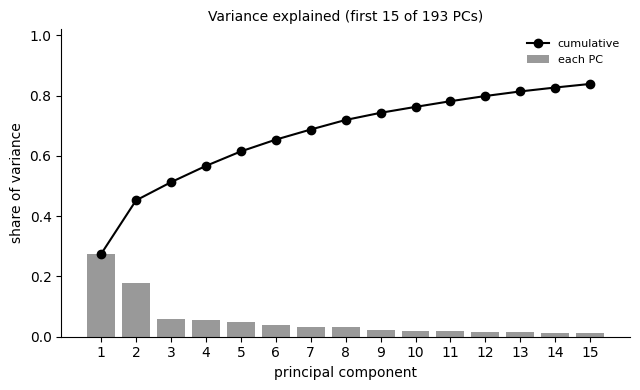

PC1 + PC2 explain 45% of the variance; PC1-PC4 explain 57%; 23 PCs reach 90%

strongest summary features on each of the first four PCs (correlation of each summary feature with the PCs):
  PC1 (27%): intruder_approach_speed -0.92, resident_approach_speed +0.91, resident_facing_end +0.75, intruder_facing_end -0.64
  PC2 (18%): arrive_ahead -0.18, resident_facing_end +0.18, start_ahead -0.12, resident_approach_speed +0.12
  PC3 (6%): start_ahead +0.53, intruder_facing_end +0.39, arrive_side -0.29, resident_speed -0.26
  PC4 (5%): intruder_facing_end +0.20, start_ahead +0.14, resident_speed -0.10, resident_straightness +0.07


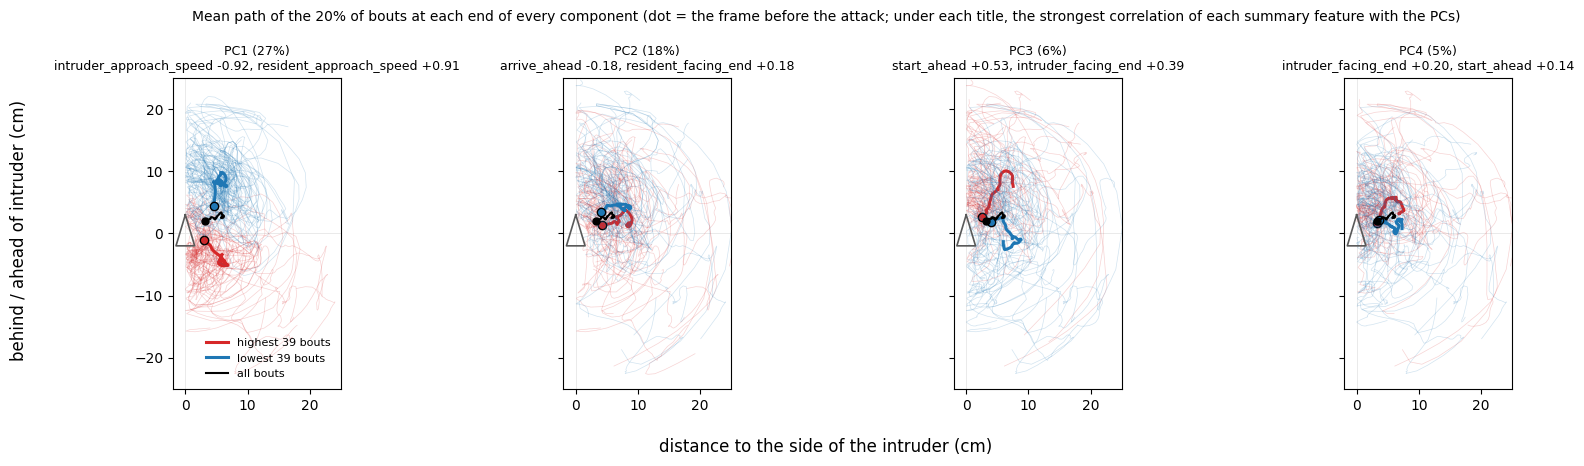

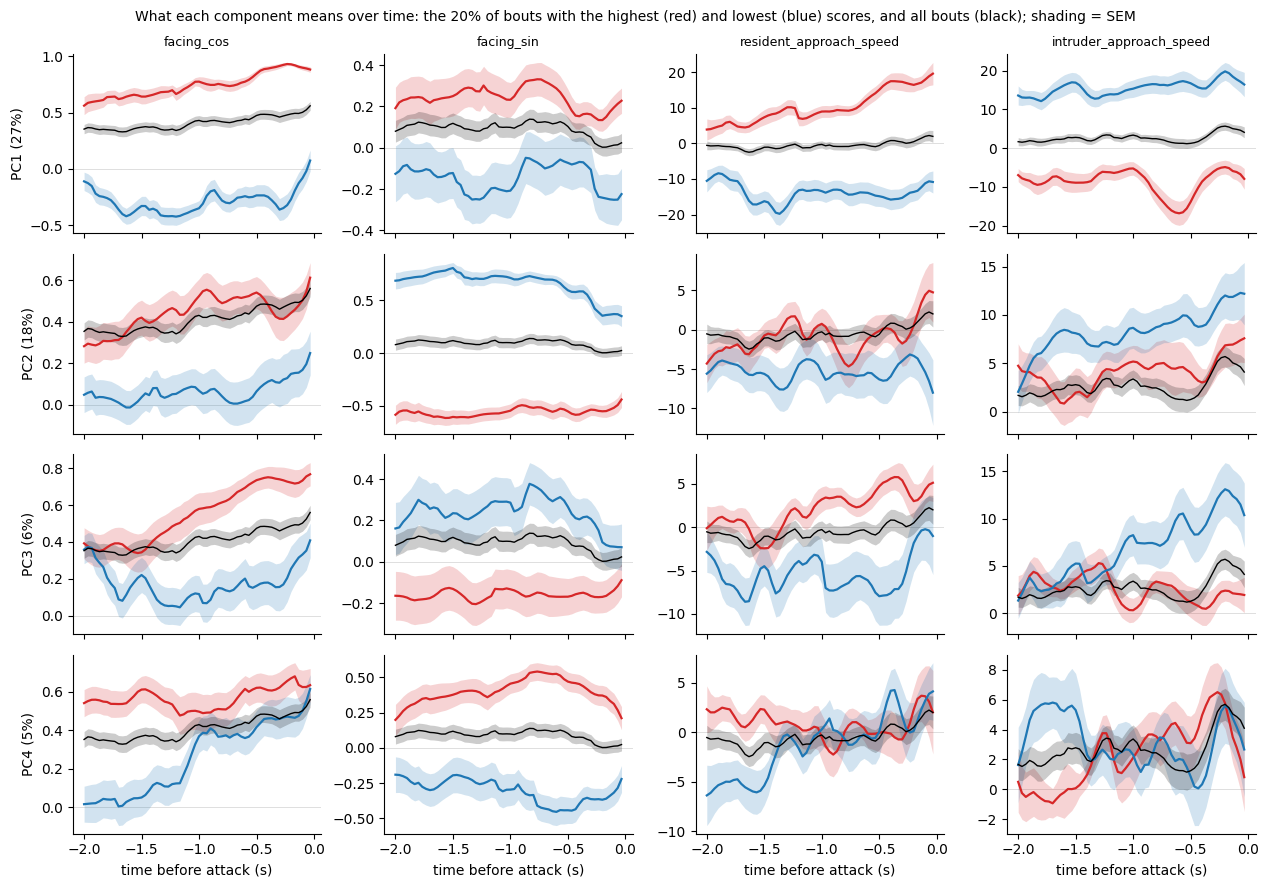

,PC1,PC2,PC3,PC4
start_distance,-0.21,0.00,0.20,-0.03
start_ahead,-0.49,-0.12,0.53,0.14
start_side,0.03,0.05,0.12,0.02
resident_speed,-0.20,-0.04,-0.26,-0.10
resident_straightness,-0.02,0.07,0.09,0.07
resident_turning,-0.05,-0.03,0.06,0.03
resident_approach_speed,0.91,0.12,0.25,0.03
intruder_approach_speed,-0.92,-0.10,-0.13,0.01
intruder_speed,-0.32,0.02,-0.25,-0.04
resident_facing_end,0.75,0.18,0.24,0.03


In [26]:
n_show = min(15, len(explained))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(np.arange(1, n_show + 1), explained[:n_show], color="0.6", label="each PC")
ax.plot(np.arange(1, n_show + 1), np.cumsum(explained)[:n_show], "o-", color="k", label="cumulative")
ax.set_xlabel("principal component"); ax.set_ylabel("share of variance"); ax.set_ylim(0, 1.02)
ax.set_xticks(np.arange(1, n_show + 1))
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Variance explained (first {n_show} of {len(explained)} PCs)", fontsize=10)
plt.tight_layout()
plt.show()

print(f"PC1 + PC2 explain {explained[:2].sum():.0%} of the variance; PC1-PC4 explain {explained[:4].sum():.0%}; "
      f"{np.searchsorted(np.cumsum(explained), 0.9) + 1} PCs reach 90%")

# arrows for the maps below: how each summary feature relates to the PCs
if FEATURES == "summary":
    arrow_table, ARROW_NOTE = loadings.iloc[:, :4], "feature loadings"
else:
    # the PCA ran on the paths, so relate the summary features to it by correlation with each PC
    arrow_table = pd.DataFrame({f"PC{k + 1}": [np.corrcoef(scaled[name], pc_scores[:, k])[0, 1] for name in scaled.columns]
                                for k in range(4)}, index=scaled.columns)
    ARROW_NOTE = "correlation of each summary feature with the PCs"

print(f"\nstrongest summary features on each of the first four PCs ({ARROW_NOTE}):")
for k, pc in enumerate(arrow_table.columns):
    top = arrow_table[pc].reindex(arrow_table[pc].abs().sort_values(ascending=False).index)[:4]
    print(f"  {pc} ({explained[k]:.0%}): " + ", ".join(f"{name} {value:+.2f}" for name, value in top.items()))

if FEATURES == "path":
    # each component is a path shape: draw the mean path, and the mean moved 2 SD along the component each way
    n_frames = paths.shape[1]
    mean_xy = pca.mean_.reshape(2, n_frames)
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharex=True, sharey=True)
    limit = np.ceil(np.abs(X.to_numpy()).max() / 5) * 5
    for k, ax in enumerate(axes):
        shift = 2 * pc_scores[:, k].std() * pca.components_[k].reshape(2, n_frames)
        for sign, color, label in [(+1, "tab:red", "+2 SD"), (-1, "tab:blue", "-2 SD")]:
            xy = mean_xy + sign * shift
            ax.plot(xy[0], xy[1], color=color, linewidth=2, label=label)
            ax.plot(xy[0, -1], xy[1, -1], "o", color=color, markersize=6)          # the frame before the attack
        ax.plot(mean_xy[0], mean_xy[1], color="k", linewidth=1.5, label="mean path")
        ax.plot(mean_xy[0, -1], mean_xy[1, -1], "o", color="k", markersize=5)
        ax.plot([0, -1.5, 1.5, 0], [3, -2, -2, 3], color="0.35", linewidth=1.2)      # intruder, facing up
        ax.axhline(0, color="0.9", linewidth=0.6, zorder=0); ax.axvline(0, color="0.9", linewidth=0.6, zorder=0)
        ax.set_xlim((0 if PATH_MIRROR_LEFT_RIGHT else -limit) - 2, limit); ax.set_ylim(-limit, limit); ax.set_aspect("equal")
        ax.set_title(f"PC{k + 1} ({explained[k]:.0%})", fontsize=10)
    axes[0].legend(fontsize=8, frameon=False)
    fig.supxlabel("distance to the side of the intruder (cm)" if PATH_MIRROR_LEFT_RIGHT else "left / right of intruder (cm)")
    fig.supylabel("behind / ahead of intruder (cm)")
    fig.suptitle("What each component means as a path (dot = the frame before the attack)", fontsize=10)
    plt.tight_layout()
    plt.show()


# the actual bouts at each end of every component: mean approach path of the bouts with the
# highest (red) and lowest (blue) scores on that PC, with those bouts' own paths underneath.
# Runs in both modes; for "summary" it shows what a component's feature mix looks like as a path
EXTREME_FRACTION = 0.20    # share of bouts taken from each end of a component
n_extreme = max(1, int(round(EXTREME_FRACTION * len(paths))))
shown_xy = savgol_filter(paths, PATH_SMOOTH_WINDOW, 2, axis=1) if PATH_SMOOTH_WINDOW > 1 else paths.copy()
if PATH_MIRROR_LEFT_RIGHT:
    shown_xy[..., 0] = np.abs(shown_xy[..., 0])
limit = np.ceil(np.nanpercentile(np.abs(shown_xy), 99) / 5) * 5    # 99th percentile, so one stray path doesn't shrink the rest

fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharex=True, sharey=True)
for k, ax in enumerate(axes):
    order = np.argsort(pc_scores[:, k])
    for rows, color, label in [(order[-n_extreme:], "tab:red", f"highest {n_extreme} bouts"),
                               (order[:n_extreme], "tab:blue", f"lowest {n_extreme} bouts")]:
        for xy in shown_xy[rows]:
            ax.plot(xy[:, 0], xy[:, 1], color=color, linewidth=0.5, alpha=0.2)
        mean_path = np.nanmean(shown_xy[rows], axis=0)
        ax.plot(mean_path[:, 0], mean_path[:, 1], color=color, linewidth=2.2, label=label)
        ax.plot(mean_path[-1, 0], mean_path[-1, 1], "o", color=color, markeredgecolor="k", markersize=6)   # the frame before the attack
    all_mean = np.nanmean(shown_xy, axis=0)
    ax.plot(all_mean[:, 0], all_mean[:, 1], color="k", linewidth=1.5, label="all bouts")
    ax.plot(all_mean[-1, 0], all_mean[-1, 1], "o", color="k", markersize=5)
    ax.plot([0, -1.5, 1.5, 0], [3, -2, -2, 3], color="0.35", linewidth=1.2)      # intruder, facing up
    ax.axhline(0, color="0.9", linewidth=0.6, zorder=0); ax.axvline(0, color="0.9", linewidth=0.6, zorder=0)
    ax.set_xlim((0 if PATH_MIRROR_LEFT_RIGHT else -limit) - 2, limit); ax.set_ylim(-limit, limit); ax.set_aspect("equal")
    top = arrow_table.iloc[:, k].reindex(arrow_table.iloc[:, k].abs().sort_values(ascending=False).index)[:2]
    ax.set_title(f"PC{k + 1} ({explained[k]:.0%})\n" + ", ".join(f"{name} {value:+.2f}" for name, value in top.items()), fontsize=9)
axes[0].legend(fontsize=8, frameon=False)
fig.supxlabel("distance to the side of the intruder (cm)" if PATH_MIRROR_LEFT_RIGHT else "left / right of intruder (cm)")
fig.supylabel("behind / ahead of intruder (cm)")
fig.suptitle(f"Mean path of the {EXTREME_FRACTION:.0%} of bouts at each end of every component "
             f"(dot = the frame before the attack; under each title, the strongest {ARROW_NOTE})", fontsize=10)
plt.tight_layout()
plt.show()

if FEATURES == "kinematics":
    # each component as time courses: mean (+/- SEM) of every kinematic series used, for the bouts
    # at the high (red) and low (blue) end of the component; black = all bouts
    shown_series = [name for block_name, weight in KINEMATIC_BLOCK_WEIGHTS.items() if weight > 0
                    for name in KINEMATIC_BLOCKS[block_name] if not name.startswith("path_")]
    if shown_series:
        time_s = (np.arange(paths.shape[1]) - paths.shape[1]) / 30    # seconds before the attack
        fig, axes = plt.subplots(4, len(shown_series), figsize=(3.2 * len(shown_series), 9), sharex=True, squeeze=False)
        for k in range(4):
            order = np.argsort(pc_scores[:, k])
            for col, name in enumerate(shown_series):
                ax = axes[k, col]
                for rows, color in [(order[-n_extreme:], "tab:red"), (order[:n_extreme], "tab:blue"), (order, "k")]:
                    values = kinematic_series[name][rows]
                    mean = np.nanmean(values, axis=0)
                    sem = np.nanstd(values, axis=0) / np.sqrt(len(rows))
                    ax.plot(time_s, mean, color=color, linewidth=1.6 if color != "k" else 1.0)
                    ax.fill_between(time_s, mean - sem, mean + sem, color=color, alpha=0.2, linewidth=0)
                ax.axhline(0, color="0.85", linewidth=0.6, zorder=0)
                ax.spines[["top", "right"]].set_visible(False)
                if k == 0:
                    ax.set_title(name, fontsize=9)
                if col == 0:
                    ax.set_ylabel(f"PC{k + 1} ({explained[k]:.0%})")
        for ax in axes[-1]:
            ax.set_xlabel("time before attack (s)")
        fig.suptitle(f"What each component means over time: the {EXTREME_FRACTION:.0%} of bouts with the highest (red) "
                     f"and lowest (blue) scores, and all bouts (black); shading = SEM", fontsize=10)
        plt.tight_layout()
        plt.show()

arrow_table.round(2)


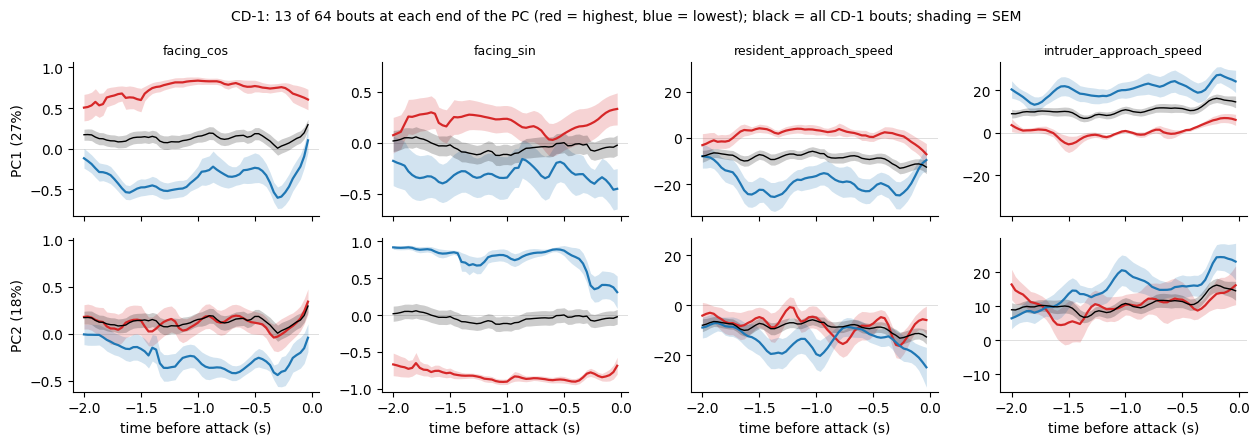

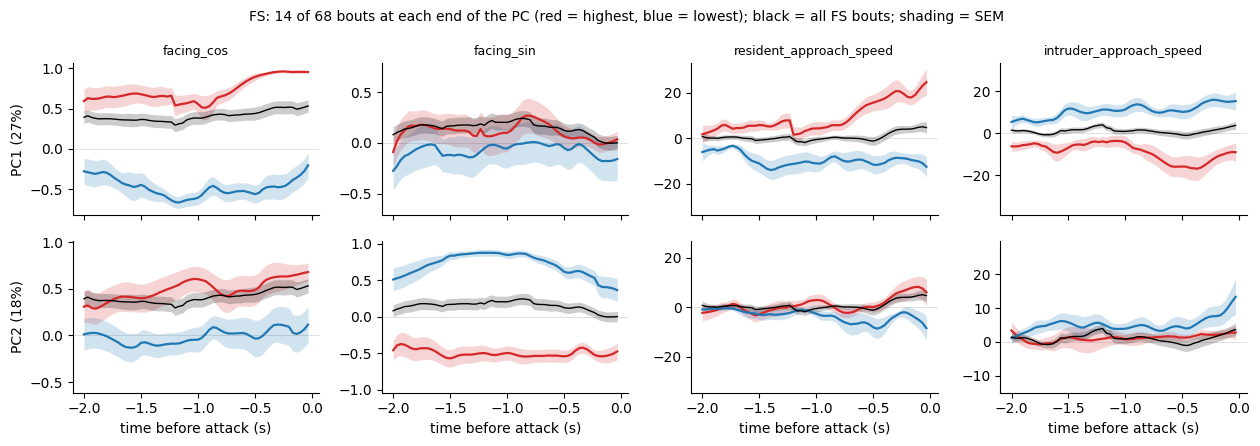

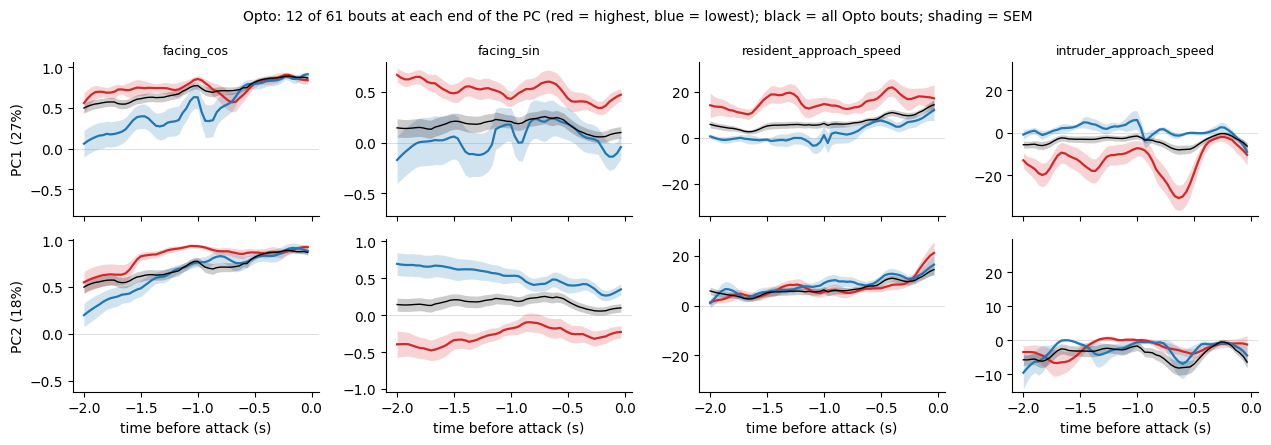

In [25]:
N_PCS_SHOWN = 2
EXTREME_FRACTION =.2
group_figs = {}
for group in GROUP_COLORS:
    group_rows = np.flatnonzero((bouts["group"] == group).to_numpy())
    n_group_extreme = max(1, int(round(EXTREME_FRACTION * len(group_rows))))
    label = GROUP_LABELS.get(group, group)

    fig, axes = plt.subplots(N_PCS_SHOWN, len(shown_series), figsize=(3.2 * len(shown_series), 2.25 * N_PCS_SHOWN),
                             sharex=True, squeeze=False)
    for k in range(N_PCS_SHOWN):
        order = group_rows[np.argsort(pc_scores[group_rows, k])]
        for col, name in enumerate(shown_series):
            ax = axes[k, col]
            for rows, color in [(order[-n_group_extreme:], "tab:red"), (order[:n_group_extreme], "tab:blue"), (order, "k")]:
                values = kinematic_series[name][rows]
                mean = np.nanmean(values, axis=0)
                sem = np.nanstd(values, axis=0) / np.sqrt(len(rows))
                ax.plot(time_s, mean, color=color, linewidth=1.6 if color != "k" else 1.0)
                ax.fill_between(time_s, mean - sem, mean + sem, color=color, alpha=0.2, linewidth=0)
            ax.axhline(0, color="0.85", linewidth=0.6, zorder=0)
            ax.spines[["top", "right"]].set_visible(False)
            if k == 0:
                ax.set_title(name, fontsize=9)
            if col == 0:
                ax.set_ylabel(f"PC{k + 1} ({explained[k]:.0%})")
    for ax in axes[-1]:
        ax.set_xlabel("time before attack (s)")
    fig.suptitle(f"{label}: {n_group_extreme} of {len(group_rows)} bouts at each end of the PC (red = highest, blue = lowest); "
                 f"black = all {label} bouts; shading = SEM", fontsize=10)
    fig.tight_layout()
    group_figs[label] = (fig, axes)

# same y range for each panel across the groups, so the figures can be compared directly
for k in range(N_PCS_SHOWN):
    for col in range(len(shown_series)):
        panels = [axes[k, col] for _, axes in group_figs.values()]
        low = min(ax.get_ylim()[0] for ax in panels)
        high = max(ax.get_ylim()[1] for ax in panels)
        for ax in panels:
            ax.set_ylim(low, high)

for label, (fig, _) in group_figs.items():
    fig.savefig(f"figures/pc_time_courses_{label}.png", dpi=300, bbox_inches="tight")

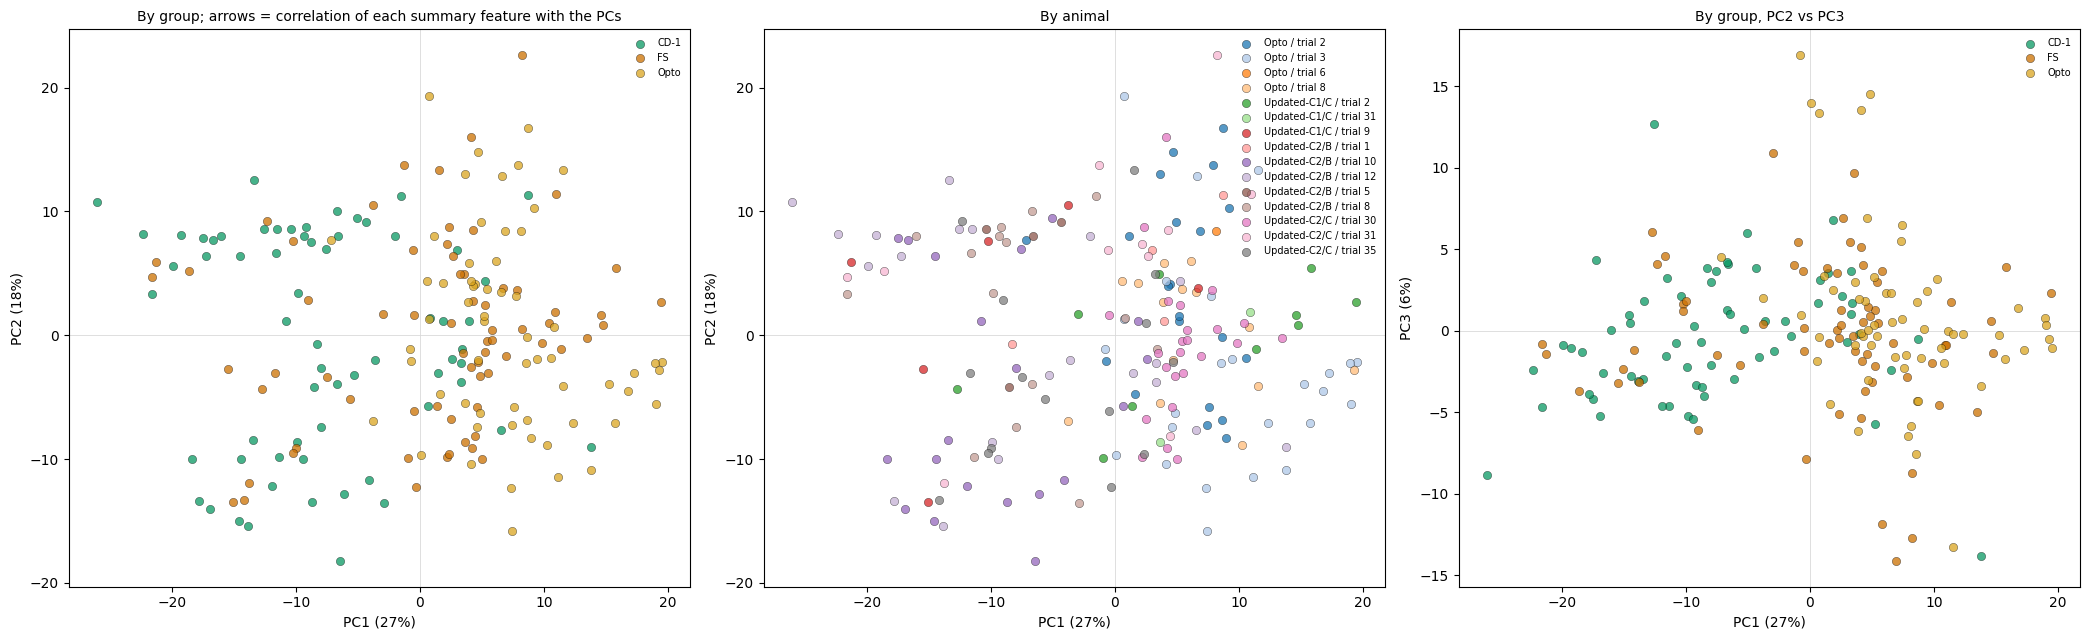

In [29]:
def pc_scatter(ax, i, j, column, colors, labels=None, arrows=False, title=""):
    """Bouts on PC i vs PC j, colored by a column of `bouts`."""
    for key, color in colors.items():
        mask = (bouts[column] == key).to_numpy()
        ax.scatter(pc_scores[mask, i], pc_scores[mask, j], s=36, color=color, alpha=0.75, edgecolor="k", linewidth=0.3,
                   label=(labels or {}).get(key, key))
    if arrows:
        # loading arrows: the direction in which each feature increases, scaled to fit the plot
        scale = 0.85 * np.abs(pc_scores[:, [i, j]]).max() / np.abs(arrow_table.iloc[:, [i, j]].to_numpy()).max()
        for name, row in arrow_table.iterrows():
            ax.annotate("", xy=(row.iloc[i] * scale, row.iloc[j] * scale), xytext=(0, 0),
                        arrowprops=dict(arrowstyle="->", color="0.25", linewidth=0.8))
            ax.text(row.iloc[i] * scale * 1.07, row.iloc[j] * scale * 1.07, name, fontsize=7, color="0.15",
                    ha="center", va="center")
    ax.axhline(0, color="0.85", linewidth=0.6, zorder=0); ax.axvline(0, color="0.85", linewidth=0.6, zorder=0)
    ax.set_xlabel(f"PC{i + 1} ({explained[i]:.0%})"); ax.set_ylabel(f"PC{j + 1} ({explained[j]:.0%})")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, frameon=False)


animal_colors = {a: plt.cm.tab20(k % 20) for k, a in enumerate(sorted(bouts["animal"].unique()))}

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
pc_scatter(axes[0], 0, 1, "group", GROUP_COLORS, GROUP_LABELS, arrows=False,
           title=f"By group; arrows = {ARROW_NOTE}")
pc_scatter(axes[1], 0, 1, "animal", animal_colors, title="By animal")
pc_scatter(axes[2], 0, 2, "group", GROUP_COLORS, GROUP_LABELS, title="By group, PC2 vs PC3")
plt.tight_layout()
plt.show()

### Where each group sits in PC1–PC2

Each panel is one group's density of bouts, scaled to that group's peak. The circles are the average position of each animal with at least 5 bouts (larger = more bouts). If a group's dense region is one animal's circle, read it as that animal, not the group.

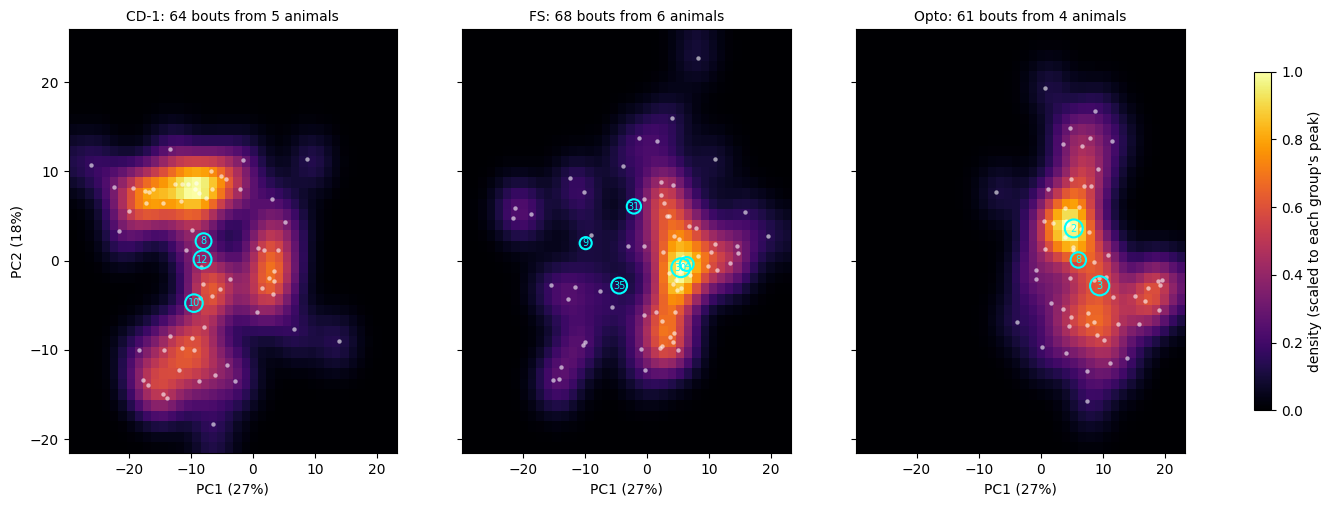

mean position of each group on PC1-PC4:
       PC1   PC2   PC3   PC4
CD-1 -7.86 -0.32 -0.47 -0.33
FS    0.90  0.09 -0.32  0.64
Opto  7.24  0.23  0.85 -0.36

saved PC1-PC4 for 193 bouts to /Users/amonast/Desktop/miniscope/data/attack_bouts/pca_kinematics_scores.csv


In [6]:
group_order = [g for g in GROUP_COLORS if g in bouts["group"].unique()]
pad = 0.08 * (pc_scores[:, :2].max(axis=0) - pc_scores[:, :2].min(axis=0))
pc_range = [[pc_scores[:, 0].min() - pad[0], pc_scores[:, 0].max() + pad[0]],
            [pc_scores[:, 1].min() - pad[1], pc_scores[:, 1].max() + pad[1]]]

fig, axes = plt.subplots(1, len(group_order), figsize=(6 * len(group_order), 5.5), sharex=True, sharey=True, squeeze=False)
for ax, group in zip(axes[0], group_order):
    in_group = (bouts["group"] == group).to_numpy()
    histogram, xe, ye = np.histogram2d(pc_scores[in_group, 0], pc_scores[in_group, 1], bins=PC_BINS, range=pc_range)
    density = gaussian_filter(histogram, PC_SMOOTH)
    im = ax.imshow((density / density.max()).T, origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]],
                   aspect="auto", cmap="inferno", vmin=0, vmax=1)
    ax.scatter(pc_scores[in_group, 0], pc_scores[in_group, 1], s=10, color="white", alpha=0.6, linewidths=0)

    for animal, rows in bouts[in_group].groupby("animal"):
        if len(rows) >= MIN_ANIMAL_BOUTS:
            cx, cy = pc_scores[rows.index, 0].mean(), pc_scores[rows.index, 1].mean()
            ax.scatter(cx, cy, s=40 + 6 * len(rows), facecolor="none", edgecolor="cyan", linewidth=1.5)
            ax.text(cx, cy, animal.split("trial ")[-1], color="cyan", fontsize=7, ha="center", va="center")

    ax.set_title(f"{GROUP_LABELS.get(group, group)}: {in_group.sum()} bouts from "
                 f"{bouts.loc[in_group, 'animal'].nunique()} animals", fontsize=10)
    ax.set_xlabel(f"PC1 ({explained[0]:.0%})")
axes[0, 0].set_ylabel(f"PC2 ({explained[1]:.0%})")
fig.colorbar(im, ax=axes, shrink=0.8, label="density (scaled to each group's peak)")
plt.show()

# group averages on the first four PCs, in units of standard deviations of the scaled features
group_means = pd.DataFrame(pc_scores[:, :4], columns=loadings.columns[:4]).groupby(bouts["group"].map(GROUP_LABELS).to_numpy()).mean()
print("mean position of each group on PC1-PC4:")
print(group_means.round(2).to_string())

pc_out = bouts[["bout_id", "group", "animal"]].copy()
for k in range(min(4, pc_scores.shape[1])):
    pc_out[f"PC{k + 1}"] = pc_scores[:, k]
pc_out.to_csv(BOUTS_DIR / f"pca_{FEATURES}_scores.csv", index=False)
print(f"\nsaved PC1-PC4 for {len(pc_out)} bouts to {BOUTS_DIR / f'pca_{FEATURES}_scores.csv'}")

### Group centroids on the first three PCs

**Left:** each group's centroid (mean position) on PC1, PC2 and PC3. PCA centers the data, so 0 is the centroid of all bouts and a group's value is its distance from that center along the component. Small dots are individual animals; the error bars are the standard error across animals.

**Right:** the distance between each pair of group centroids, on each PC and in the combined PC1–PC3 space.

With `STANDARDIZE = True` everything is in units of each PC's standard deviation across all bouts, so the three PCs can share an axis.

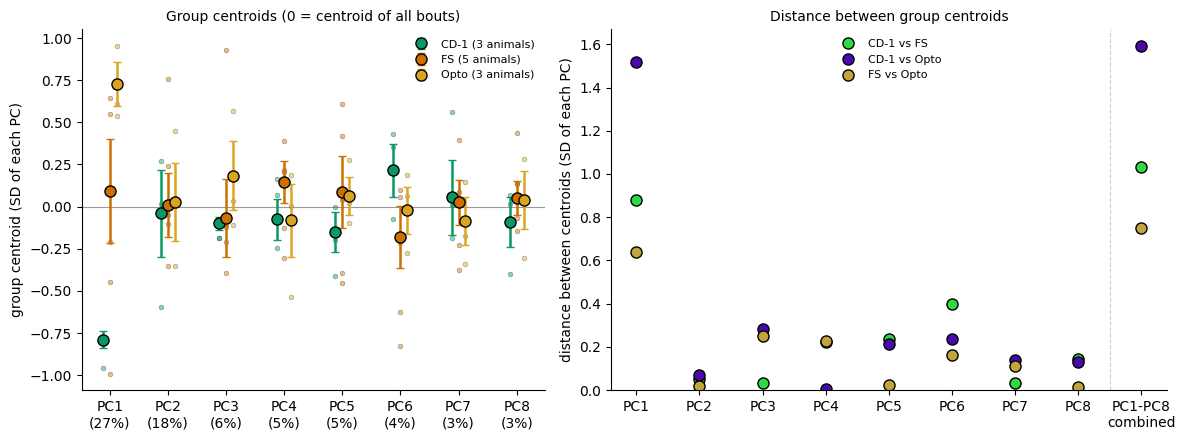

group centroids (SD of each PC):
        PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
group                                                
CD-1  -0.79 -0.04 -0.10 -0.08 -0.15  0.22  0.06 -0.09
FS     0.09  0.01 -0.07  0.15  0.09 -0.18  0.02  0.05
Opto   0.73  0.03  0.18 -0.08  0.06 -0.02 -0.09  0.04

distance between group centroids (SD of each PC):
               PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8  PC1-PC8 combined
CD-1 vs FS    0.88  0.05  0.03  0.22  0.24  0.40  0.03  0.14              1.03
CD-1 vs Opto  1.52  0.07  0.28  0.01  0.21  0.24  0.14  0.13              1.59
FS vs Opto    0.64  0.02  0.25  0.23  0.02  0.16  0.11  0.01              0.75


In [7]:
N_PCS = 8
STANDARDIZE = True          # True: units of each PC's SD across all bouts; False: raw PC scores
CENTROID_SAVE_PATH = f"figures/pca_{FEATURES}_group_centroids.png"   # set to None to skip saving

pcs = [f"PC{k + 1}" for k in range(N_PCS)]
scores = pc_scores[:, :N_PCS] / (pc_scores[:, :N_PCS].std(axis=0) if STANDARDIZE else 1)
score_df = pd.DataFrame(scores, columns=pcs)
score_df["group"], score_df["animal"] = bouts["group"].to_numpy(), bouts["animal"].to_numpy()
unit = "SD of each PC" if STANDARDIZE else "PC score"

group_order = [g for g in GROUP_COLORS if g in bouts["group"].unique()]
centroids = score_df.groupby("group")[pcs].mean().loc[group_order]                 # mean over all of a group's bouts
animal_means = score_df.groupby(["group", "animal"])[pcs].mean()
animal_n = score_df.groupby(["group", "animal"]).size()
animal_means = animal_means[animal_n >= MIN_ANIMAL_BOUTS]                          # animals with enough bouts

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})

# left: centroid of each group on each PC
x = np.arange(N_PCS)
for k, group in enumerate(group_order):
    offset = (k - (len(group_order) - 1) / 2) * 0.12
    color = GROUP_COLORS[group]
    per_animal = animal_means.loc[group] if group in animal_means.index.get_level_values(0) else pd.DataFrame(columns=pcs)
    for _, row in per_animal.iterrows():
        ax1.plot(x + offset, row[pcs].to_numpy(dtype=float), "o", color=color, markersize=3.5, alpha=0.45,
                 markeredgecolor="k", markeredgewidth=0.3, zorder=2)
    sem = per_animal.std() / np.sqrt(len(per_animal)) if len(per_animal) > 1 else pd.Series(0.0, index=pcs)
    ax1.errorbar(x + offset, centroids.loc[group, pcs].to_numpy(), yerr=sem[pcs].to_numpy(dtype=float), fmt="o", color=color,
                 markeredgecolor="k", markersize=8, elinewidth=1.8, capsize=3, zorder=3,
                 label=f"{GROUP_LABELS.get(group, group)} ({len(per_animal)} animals)")
ax1.axhline(0, color="0.6", linewidth=0.8, zorder=1)
ax1.set_xticks(x); ax1.set_xticklabels([f"{pc}\n({explained[i]:.0%})" for i, pc in enumerate(pcs)])
ax1.set_ylabel(f"group centroid ({unit})")
ax1.set_title("Group centroids (0 = centroid of all bouts)", fontsize=10)
ax1.legend(frameon=False, fontsize=8); ax1.spines[["top", "right"]].set_visible(False)

# right: distance between each pair of group centroids, per PC and in PC1-PC3 together
pairs = [(a, b) for i, a in enumerate(group_order) for b in group_order[i + 1:]]
labels = pcs + [f"PC1-PC{N_PCS}\ncombined"]
distance_rows = {}
for a, b in pairs:
    difference = (centroids.loc[a, pcs] - centroids.loc[b, pcs]).to_numpy(dtype=float)
    values = np.r_[np.abs(difference), np.linalg.norm(difference)]
    name = f"{GROUP_LABELS.get(a, a)} vs {GROUP_LABELS.get(b, b)}"
    distance_rows[name] = values
    ax2.plot(np.arange(len(labels)), values, "o", color=PAIR_COLORS[frozenset({GROUP_LABELS.get(a, a), GROUP_LABELS.get(b, b)})],
             markeredgecolor="k", markersize=8, label=name)
ax2.axvline(N_PCS - 0.5, color="0.8", linewidth=0.8, linestyle="--")
ax2.set_xticks(np.arange(len(labels))); ax2.set_xticklabels(labels)
ax2.set_ylabel(f"distance between centroids ({unit})"); ax2.set_ylim(bottom=0)
ax2.set_title("Distance between group centroids", fontsize=10)
ax2.legend(frameon=False, fontsize=8); ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
if CENTROID_SAVE_PATH:
    plt.savefig(CENTROID_SAVE_PATH, dpi=300)
plt.show()

print(f"group centroids ({unit}):")
print(centroids.rename(index=GROUP_LABELS).round(2).to_string())
print(f"\ndistance between group centroids ({unit}):")
print(pd.DataFrame(distance_rows, index=[l.replace(chr(10), " ") for l in labels]).T.round(2).to_string())

In [8]:
import pingouin as pg

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.7.0.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [9]:
animal_means_long = animal_means.reset_index().melt(
    id_vars=["group", "animal"],      # columns to keep on every row
    value_vars=pcs,                   # ["PC1", "PC2", "PC3"]: the columns to stack
    var_name="pc",                    # new column holding "PC1" / "PC2" / "PC3"
    value_name="score",               # new column holding the values
)

In [10]:
pg.mixed_anova(data=animal_means_long, dv="score", within="pc", between="group", subject="animal")

,Source,SS,DF1,DF2,MS,F,p-unc,np2,eps
0,group,0.601703,2,8,0.300851,1.368599,0.308174,0.254927,NaN
1,pc,0.137372,7,56,0.019625,0.156447,0.992404,0.019181,0.502234
2,Interaction,4.218013,14,56,0.301287,2.401852,0.010493,0.375181,NaN


/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/1248544810.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, width=0.55,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/1248544810.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, size=3.5, alpha=0.6,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/1248544810.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels([f"{g}\n(n={(box_df['group'] == g).sum()})" for g in box_order])
/var/folders/4k

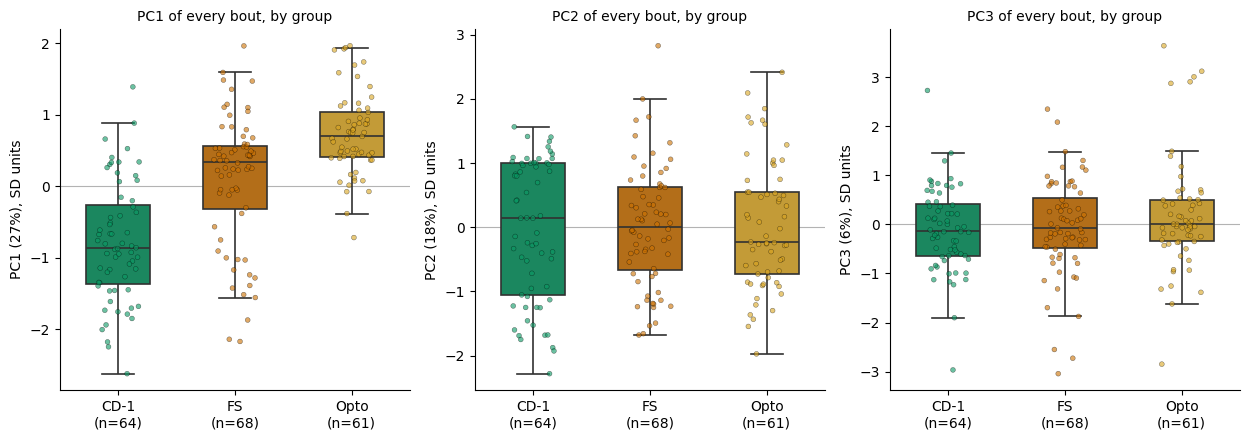


PC1
       count  mean   25%   50%   75%
group                               
CD-1    64.0 -0.79 -1.36 -0.87 -0.27
FS      68.0  0.09 -0.32  0.34  0.56
Opto    61.0  0.73  0.41  0.69  1.03

PC2
       count  mean   25%   50%   75%
group                               
CD-1    64.0 -0.04 -1.06  0.14  1.00
FS      68.0  0.01 -0.66  0.01  0.62
Opto    61.0  0.03 -0.73 -0.23  0.55

PC3
       count  mean   25%   50%   75%
group                               
CD-1    64.0 -0.10 -0.64 -0.13  0.41
FS      68.0 -0.07 -0.47 -0.08  0.53
Opto    61.0  0.18 -0.35  0.00  0.50


In [28]:
# box plots of every bout's score on each component, by group (one panel per component)
import seaborn as sns

BOX_PCS = [1, 2, 3,]          # which components (1 = PC1)
BOX_SAVE_PATH = f"figures/pca_{FEATURES}_pc{'-'.join(str(pc) for pc in BOX_PCS)}_by_group.png"   # set to None to skip saving

box_order = [GROUP_LABELS[g] for g in GROUP_COLORS if g in bouts["group"].unique()]
box_palette = {GROUP_LABELS[g]: color for g, color in GROUP_COLORS.items()}
box_groups = bouts["group"].map(GROUP_LABELS).to_numpy()

fig, axes = plt.subplots(1, len(BOX_PCS), figsize=(4.2 * len(BOX_PCS), 4.5), squeeze=False)
box_dfs = {}
for ax, box_pc in zip(axes[0], BOX_PCS):
    box_scores = pc_scores[:, box_pc - 1] / (pc_scores[:, box_pc - 1].std() if STANDARDIZE else 1)
    box_df = box_dfs[box_pc] = pd.DataFrame({"group": box_groups, "score": box_scores})

    sns.boxplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, width=0.55,
                linewidth=1.2, fliersize=0, ax=ax)                       # fliersize=0: the dots below already show every bout
    sns.stripplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, size=3.5, alpha=0.6,
                  jitter=0.18, edgecolor="k", linewidth=0.3, ax=ax)      # one dot per bout
    ax.axhline(0, color="0.7", linewidth=0.8, zorder=0)
    ax.set_xticklabels([f"{g}\n(n={(box_df['group'] == g).sum()})" for g in box_order])
    ax.set_xlabel("")
    ax.set_ylabel(f"PC{box_pc} ({explained[box_pc - 1]:.0%})" + (", SD units" if STANDARDIZE else ""))
    ax.set_title(f"PC{box_pc} of every bout, by group", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
if BOX_SAVE_PATH:
    plt.savefig(BOX_SAVE_PATH, dpi=300)
plt.show()

for box_pc, box_df in box_dfs.items():
    print(f"\nPC{box_pc}")
    print(box_df.groupby("group")["score"].describe().loc[box_order, ["count", "mean", "25%", "50%", "75%"]].round(2).to_string())


### Do the groups differ on PC1? Mixed-effects model

`score ~ group`, with a random intercept for each animal. Every bout is used, but bouts from the same animal are treated as related, so an animal with many bouts doesn't count as many independent samples.

- **Overall test:** a likelihood-ratio test of the model with group against the model without it.
- **Pairwise:** the estimated difference between each pair of groups, with a 95% interval and Holm-corrected p-values.
- **ICC:** the share of the variation that is between animals. A high value means bouts from one animal are alike, and the effective sample size is closer to the number of animals than the number of bouts.

With only a handful of animals per group, treat the p-values as approximate: they rely on large-sample theory.

In [12]:
import statsmodels.formula.api as smf
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests

MIXED_PC = 1        # which component to test (1 = PC1)

score = pc_scores[:, MIXED_PC - 1]
mixed_df = pd.DataFrame({
    "score": score / score.std(),                              # in SD units of this PC across all bouts
    "group": bouts["group"].map(GROUP_LABELS).to_numpy(),
    "animal": bouts["animal"].to_numpy(),
})
print(f"PC{MIXED_PC} ({explained[MIXED_PC - 1]:.0%} of the variance): {len(mixed_df)} bouts, "
      f"{mixed_df['animal'].nunique()} animals; animals per group: {mixed_df.groupby('group')['animal'].nunique().to_dict()}")

def fit_mixed(formula, reml):
    # "powell" converges reliably here; the default optimizer can fail when the animal variance is small
    return smf.mixedlm(formula, mixed_df, groups=mixed_df["animal"]).fit()


# the model, fitted with REML for the estimates
model = fit_mixed("score ~ C(group)", reml=True)

# overall effect of group: likelihood-ratio test (both models fitted with ML, as the test requires)
with_group = fit_mixed("score ~ C(group)", reml=False)
without_group = fit_mixed("score ~ 1", reml=False)
lr = 2 * (with_group.llf - without_group.llf)
df_group = mixed_df["group"].nunique() - 1
print(f"\noverall effect of group: chi2({df_group}) = {lr:.2f}, p = {chi2.sf(lr, df_group):.4g}")

# how much of the variation is between animals
animal_var, residual_var = float(model.cov_re.iloc[0, 0]), float(model.scale)
print(f"between-animal variance {animal_var:.3f}, within-animal variance {residual_var:.3f} "
      f"-> ICC = {animal_var / (animal_var + residual_var):.2f}")

# estimated mean of each group, and every pairwise difference, as contrasts of the fixed effects
group_names = sorted(mixed_df["group"].unique())               # the first is the model's reference group


def contrast(weights):
    """Estimate, SE, 95% CI and p-value for a weighted sum of the group means."""
    vector = pd.Series(0.0, index=model.fe_params.index)        # one entry per fixed effect
    vector["Intercept"] = sum(weights.values())
    for name, w in weights.items():
        if name != group_names[0]:
            vector[f"C(group)[T.{name}]"] = w
    test = model.t_test(vector.to_numpy()[None, :])
    low, high = np.ravel(test.conf_int())
    return float(np.ravel(test.effect)[0]), float(np.ravel(test.sd)[0]), float(low), float(high), float(np.ravel(test.pvalue)[0])


means = pd.DataFrame({name: contrast({name: 1.0})[:4] for name in group_names},
                     index=["estimated mean", "SE", "95% low", "95% high"]).T
print("\nestimated group means (SD units):")
print(means.round(2).to_string())

rows = []
for i, a in enumerate(group_names):
    for b in group_names[i + 1:]:
        estimate, se, low, high, pvalue = contrast({a: 1.0, b: -1.0})
        rows.append({"comparison": f"{a} - {b}", "difference": estimate, "SE": se, "95% low": low, "95% high": high, "p": pvalue})
pairwise = pd.DataFrame(rows).set_index("comparison")
pairwise["p (Holm)"] = multipletests(pairwise["p"], method="holm")[1]
print("\npairwise differences (SD units):")
print(pairwise.round(3).to_string())

PC1 (27% of the variance): 193 bouts, 15 animals; animals per group: {'CD-1': 5, 'FS': 6, 'Opto': 4}

overall effect of group: chi2(2) = 10.41, p = 0.005503
between-animal variance 0.190, within-animal variance 0.518 -> ICC = 0.27

estimated group means (SD units):
      estimated mean    SE  95% low  95% high
CD-1           -0.68  0.22    -1.12     -0.24
FS              0.02  0.21    -0.39      0.42
Opto            0.71  0.26     0.21      1.22

pairwise differences (SD units):
             difference     SE  95% low  95% high      p  p (Holm)
comparison                                                        
CD-1 - FS        -0.697  0.305   -1.296    -0.099  0.022     0.045
CD-1 - Opto      -1.392  0.341   -2.060    -0.724  0.000     0.000
FS - Opto        -0.695  0.330   -1.341    -0.049  0.035     0.045


### Pairwise distances between bouts in PC space

Distance between every pair of bouts in PC space. `DIST_METRIC` sets how:

- `"mahalanobis"` (default): each PC is divided by its SD, so every component counts equally. Uses the first `DIST_PCS` PCs, or with `None`, as many as reach `DIST_VARIANCE` (90%) of the variance; the remaining small components are left out because, scaled up, they are mostly noise.
- `"euclidean"`: raw PC scores, so PC1 counts more than later components, in proportion to how much each varies. `None` uses every dimension, the same as distance in the original features.


- The matrix shows every pair, with bouts ordered by group and then animal.
- The table compares distances within and between groups. If groups occupy different regions, between-group distances are larger than within-group ones.
- Pairs from the same animal are separated out: if they are much closer than pairs from different animals of the same group, the map is partly sorting individuals.

Mahalanobis distance, PC1-PC10 (76% of variance)


/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/3498506459.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=between, x="group_pair", y="distance", order=pair_labels, ax=ax4, linewidth=1.2, fliersize=1.5,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/3498506459.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax5,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_28855/3498506459.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `lege

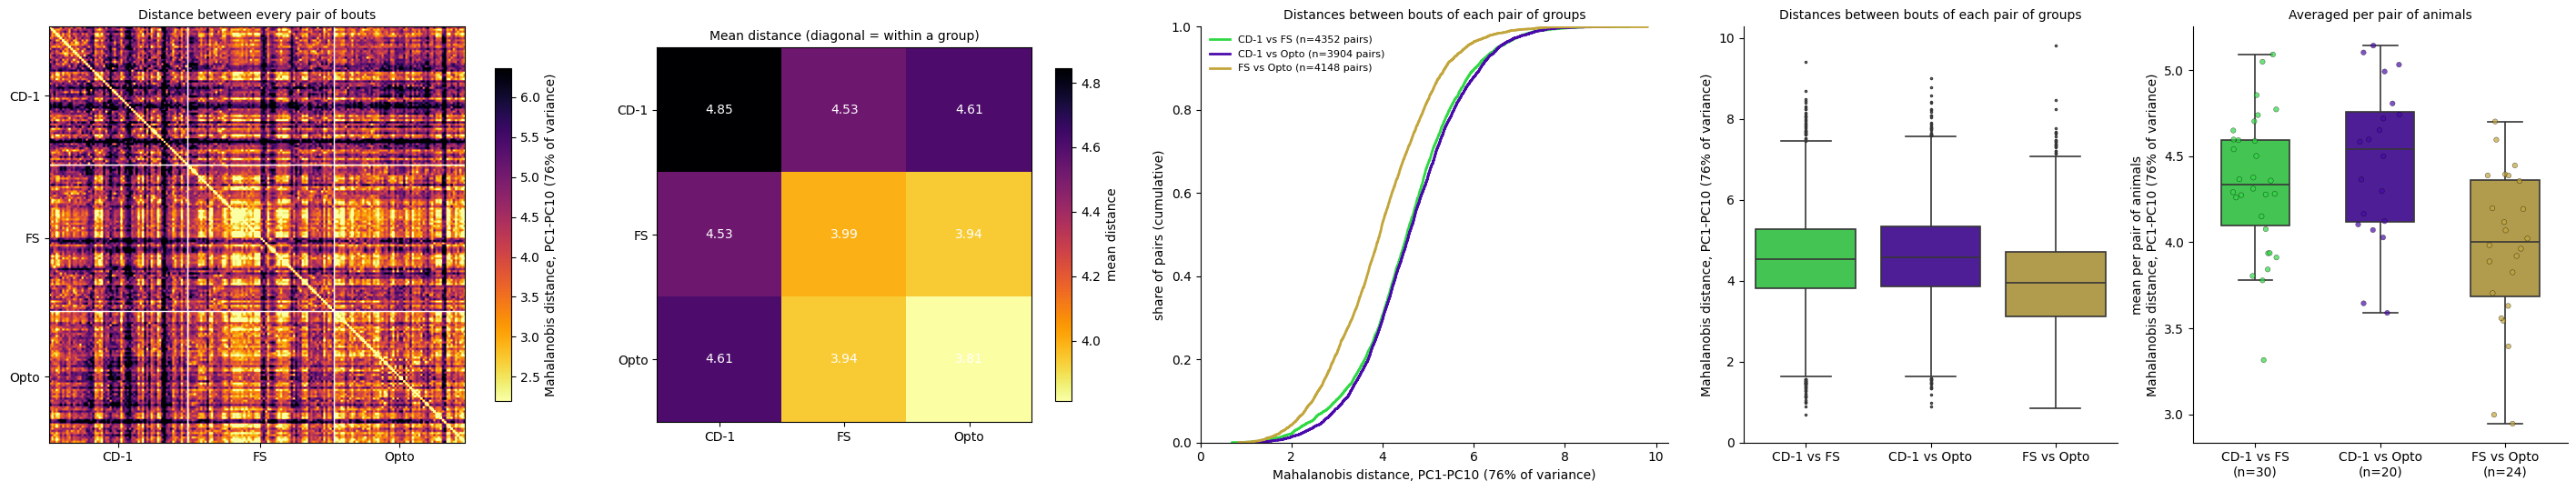

mean Mahalanobis distance, PC1-PC10 (76% of variance) between bouts (diagonal = within a group):
      CD-1    FS  Opto
CD-1  4.85  4.53  4.61
FS    4.53  3.99  3.94
Opto  4.61  3.94  3.81

by kind of pair:
                               mean  median   size
pair_type                                         
same animal                    4.09    4.11   1615
same group, different animals  4.27    4.26   4509
different groups               4.36    4.35  12404

saved the 193 x 193 matrix to /Users/amonast/Desktop/miniscope/data/attack_bouts/pca_kinematics_pairwise_distances_mahalanobis_pc10.csv


In [13]:
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

DIST_METRIC = "mahalanobis"   # "mahalanobis": every PC in units of its own SD, so each counts equally;
                              # "euclidean": raw PC scores, so each PC counts in proportion to its variance
DIST_PCS = 10                  # number of PCs (2 = the map). None: for "mahalanobis", as many as reach
                              # DIST_VARIANCE; for "euclidean", every dimension (the same as distance in X)
DIST_VARIANCE = 0.90          # share of variance the PCs must reach when DIST_PCS is None (mahalanobis)

if DIST_METRIC == "mahalanobis":
    # dividing each PC by its SD makes Euclidean distance on the scores the Mahalanobis distance within
    # those PCs. The small last components are left out on purpose: scaled up to SD 1 they would be mostly noise
    n_dist_pcs = DIST_PCS or int(np.searchsorted(np.cumsum(explained), DIST_VARIANCE) + 1)
    if n_dist_pcs > pc_scores.shape[1]:
        print(f"note: {DIST_VARIANCE:.0%} of the variance needs {n_dist_pcs} PCs, but the PCA kept {pc_scores.shape[1]}; using those")
        n_dist_pcs = pc_scores.shape[1]
    dist_points = pc_scores[:, :n_dist_pcs] / pc_scores[:, :n_dist_pcs].std(axis=0)
    dist_label = f"Mahalanobis distance, PC1-PC{n_dist_pcs} ({explained[:n_dist_pcs].sum():.0%} of variance)"
    dist_tag = f"mahalanobis_pc{n_dist_pcs}"
elif DIST_METRIC == "euclidean":
    # all components together are only a rotation of X, so distance with every component is distance in X
    dist_points = X.to_numpy() if DIST_PCS is None else pc_scores[:, :DIST_PCS]
    dist_label = f"Euclidean distance, all {X.shape[1]} dimensions" if DIST_PCS is None else f"Euclidean distance, PC1-PC{DIST_PCS}"
    dist_tag = "euclidean_all" if DIST_PCS is None else f"euclidean_pc{DIST_PCS}"
else:
    raise ValueError(f"unknown DIST_METRIC: {DIST_METRIC!r}")
DIST_SAVE_PATH = BOUTS_DIR / f"pca_{FEATURES}_pairwise_distances_{dist_tag}.csv"   # set to None to skip saving
print(dist_label)

pc_distances = squareform(pdist(dist_points, metric="euclidean"))    # [n_bouts, n_bouts]
distance_df = pd.DataFrame(pc_distances, index=bouts["bout_id"], columns=bouts["bout_id"])
if DIST_SAVE_PATH:
    distance_df.to_csv(DIST_SAVE_PATH)

# long form: each pair of bouts once
i, j = np.triu_indices(len(bouts), k=1)
group_label = bouts["group"].map(GROUP_LABELS).to_numpy()
animal = bouts["animal"].to_numpy()
pairs = pd.DataFrame({
    "bout_a": bouts["bout_id"].to_numpy()[i], "bout_b": bouts["bout_id"].to_numpy()[j],
    "group_a": group_label[i], "group_b": group_label[j],
    "animal_a": animal[i], "animal_b": animal[j],
    "same_animal": animal[i] == animal[j],
    "distance": pc_distances[i, j],
})
pairs["pair_type"] = np.where(pairs["same_animal"], "same animal",
                     np.where(pairs["group_a"] == pairs["group_b"], "same group, different animals", "different groups"))

group_names = [GROUP_LABELS[g] for g in GROUP_COLORS if g in bouts["group"].unique()]
mean_distance = pd.DataFrame(index=group_names, columns=group_names, dtype=float)
for a in group_names:
    for b in group_names:
        in_pair = ((pairs["group_a"] == a) & (pairs["group_b"] == b)) | ((pairs["group_a"] == b) & (pairs["group_b"] == a))
        mean_distance.loc[a, b] = pairs.loc[in_pair, "distance"].mean()

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(29, 5.5), gridspec_kw={"width_ratios": [1.25, 1, 1, 0.8, 0.8]})
cmap='inferno_r'
# every pair, ordered by group then animal
order = bouts.assign(label=group_label).sort_values(["label", "animal", "bout_id"]).index.to_numpy()
im = ax1.imshow(pc_distances[np.ix_(order, order)], cmap=cmap, vmin=np.percentile(pc_distances, 5),vmax=np.percentile(pc_distances, 95))   # top 5% of distances share one color
plt.colorbar(im, ax=ax1, shrink=0.8, label=dist_label)
sorted_groups = group_label[order]
edges = np.flatnonzero(sorted_groups[1:] != sorted_groups[:-1]) + 1
for e in edges:
    ax1.axhline(e - 0.5, color="white", linewidth=1); ax1.axvline(e - 0.5, color="white", linewidth=1)
starts, ends = np.r_[0, edges], np.r_[edges, len(order)]
ax1.set_xticks((starts + ends) / 2 - 0.5); ax1.set_xticklabels(sorted_groups[starts])
ax1.set_yticks((starts + ends) / 2 - 0.5); ax1.set_yticklabels(sorted_groups[starts])
ax1.set_title("Distance between every pair of bouts", fontsize=10)

# mean distance within and between groups
im2 = ax2.imshow(mean_distance.to_numpy(), cmap=cmap)
for r in range(len(group_names)):
    for c in range(len(group_names)):
        ax2.text(c, r, f"{mean_distance.iloc[r, c]:.2f}", ha="center", va="center", color="white", fontsize=10)
ax2.set_xticks(range(len(group_names))); ax2.set_xticklabels(group_names)
ax2.set_yticks(range(len(group_names))); ax2.set_yticklabels(group_names)
plt.colorbar(im2, ax=ax2, shrink=0.8, label="mean distance")
ax2.set_title("Mean distance (diagonal = within a group)", fontsize=10)

# distribution of the distances between bouts of each pair of groups
group_pairs = [(a, b) for k, a in enumerate(group_names) for b in group_names[k + 1:]]
for a, b in group_pairs:
    in_pair = ((pairs["group_a"] == a) & (pairs["group_b"] == b)) | ((pairs["group_a"] == b) & (pairs["group_b"] == a))
    sns.ecdfplot(x=pairs.loc[in_pair, "distance"], ax=ax3, color=PAIR_COLORS[frozenset({a, b})], linewidth=2,
                 label=f"{a} vs {b} (n={in_pair.sum()} pairs)")
ax3.set_xlim(left=0)
ax3.set_xlabel(dist_label); ax3.set_ylabel("share of pairs (cumulative)")
ax3.legend(frameon=False, fontsize=8); ax3.spines[["top", "right"]].set_visible(False)
ax3.set_title("Distances between bouts of each pair of groups", fontsize=10)

# the same distances as box plots: one box per pair of groups, same colors as the curves
between = pairs[pairs["group_a"] != pairs["group_b"]].copy()
pair_labels = [f"{a} vs {b}" for a, b in group_pairs]
label_of = {frozenset(pair): label for pair, label in zip(group_pairs, pair_labels)}
between["group_pair"] = [label_of[frozenset(pair)] for pair in zip(between["group_a"], between["group_b"])]
pair_palette = {label: PAIR_COLORS[frozenset(pair)] for label, pair in zip(pair_labels, group_pairs)}
sns.boxplot(data=between, x="group_pair", y="distance", order=pair_labels, ax=ax4, linewidth=1.2, fliersize=1.5,
            palette=pair_palette)
ax4.set_ylim(bottom=0)
ax4.set_xlabel(""); ax4.set_ylabel(dist_label)
ax4.spines[["top", "right"]].set_visible(False)
ax4.set_title("Distances between bouts of each pair of groups", fontsize=10)

# the same, averaged per pair of animals: the mean distance over all pairs of their bouts, one dot
# per pair of animals, so animals with many bouts don't dominate
between["animal_pair"] = [" & ".join(sorted(pair)) for pair in zip(between["animal_a"], between["animal_b"])]
animal_pair_means = between.groupby(["group_pair", "animal_pair"], as_index=False)["distance"].mean()
sns.boxplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax5,
            width=0.55, linewidth=1.2, fliersize=0)                 # fliersize=0: the dots show every pair of animals
sns.stripplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax5,
              size=4, alpha=0.7, jitter=0.18, edgecolor="k", linewidth=0.3)
ax5.set_xticklabels([f"{label}\n(n={(animal_pair_means['group_pair'] == label).sum()})" for label in pair_labels])
ax5.set_xlabel(""); ax5.set_ylabel(f"mean per pair of animals\n{dist_label}")
ax5.spines[["top", "right"]].set_visible(False)
ax5.set_title("Averaged per pair of animals", fontsize=10)

plt.tight_layout()
plt.show()

print(f"mean {dist_label} between bouts (diagonal = within a group):")
print(mean_distance.round(2).to_string())
types = ["same animal", "same group, different animals", "different groups"]
print("\nby kind of pair:")
print(pairs.groupby("pair_type")["distance"].agg(["mean", "median", "size"]).loc[types].round(2).to_string())
if DIST_SAVE_PATH:
    print(f"\nsaved the {len(bouts)} x {len(bouts)} matrix to {DIST_SAVE_PATH}")

In [14]:
animal_pair_means

,group_pair,animal_pair,distance
0,CD-1 vs FS,Updated-C1/C / trial 2 & Updated-C2/B / trial 1,4.273600
1,CD-1 vs FS,Updated-C1/C / trial 2 & Updated-C2/B / trial 10,4.771497
2,CD-1 vs FS,Updated-C1/C / trial 2 & Updated-C2/B / trial 12,5.090236
3,CD-1 vs FS,Updated-C1/C / trial 2 & Updated-C2/B / trial 5,4.539834
4,CD-1 vs FS,Updated-C1/C / trial 2 & Updated-C2/B / trial 8,5.047998
...,...,...,...
69,FS vs Opto,Opto / trial 8 & Updated-C1/C / trial 31,2.998273
70,FS vs Opto,Opto / trial 8 & Updated-C1/C / trial 9,3.920280
71,FS vs Opto,Opto / trial 8 & Updated-C2/C / trial 30,3.558956
72,FS vs Opto,Opto / trial 8 & Updated-C2/C / trial 31,3.888418


In [15]:
pg.anova(data=animal_pair_means,dv='distance',between='group_pair')

,Source,ddof1,ddof2,F,p-unc,np2
0,group_pair,2,71,8.05668,0.000703,0.18497


## Watershed clusters on the PC1–PC2 map

The same peak-seeded watershed as the UMAP: each cluster grows from a peak in the density of bouts, and the boundaries fall in the sparser gaps. Here the clusters are landmarks for comparing groups, not a claim that the bouts fall into separate types.

The cluster settings are at the top of the next cell. Change them and re-run from that cell down.

asked for up to 6 clusters, got 6 with bouts in them: 1 (n=53), 2 (n=69), 3 (n=22), 4 (n=22), 5 (n=14), 6 (n=13)


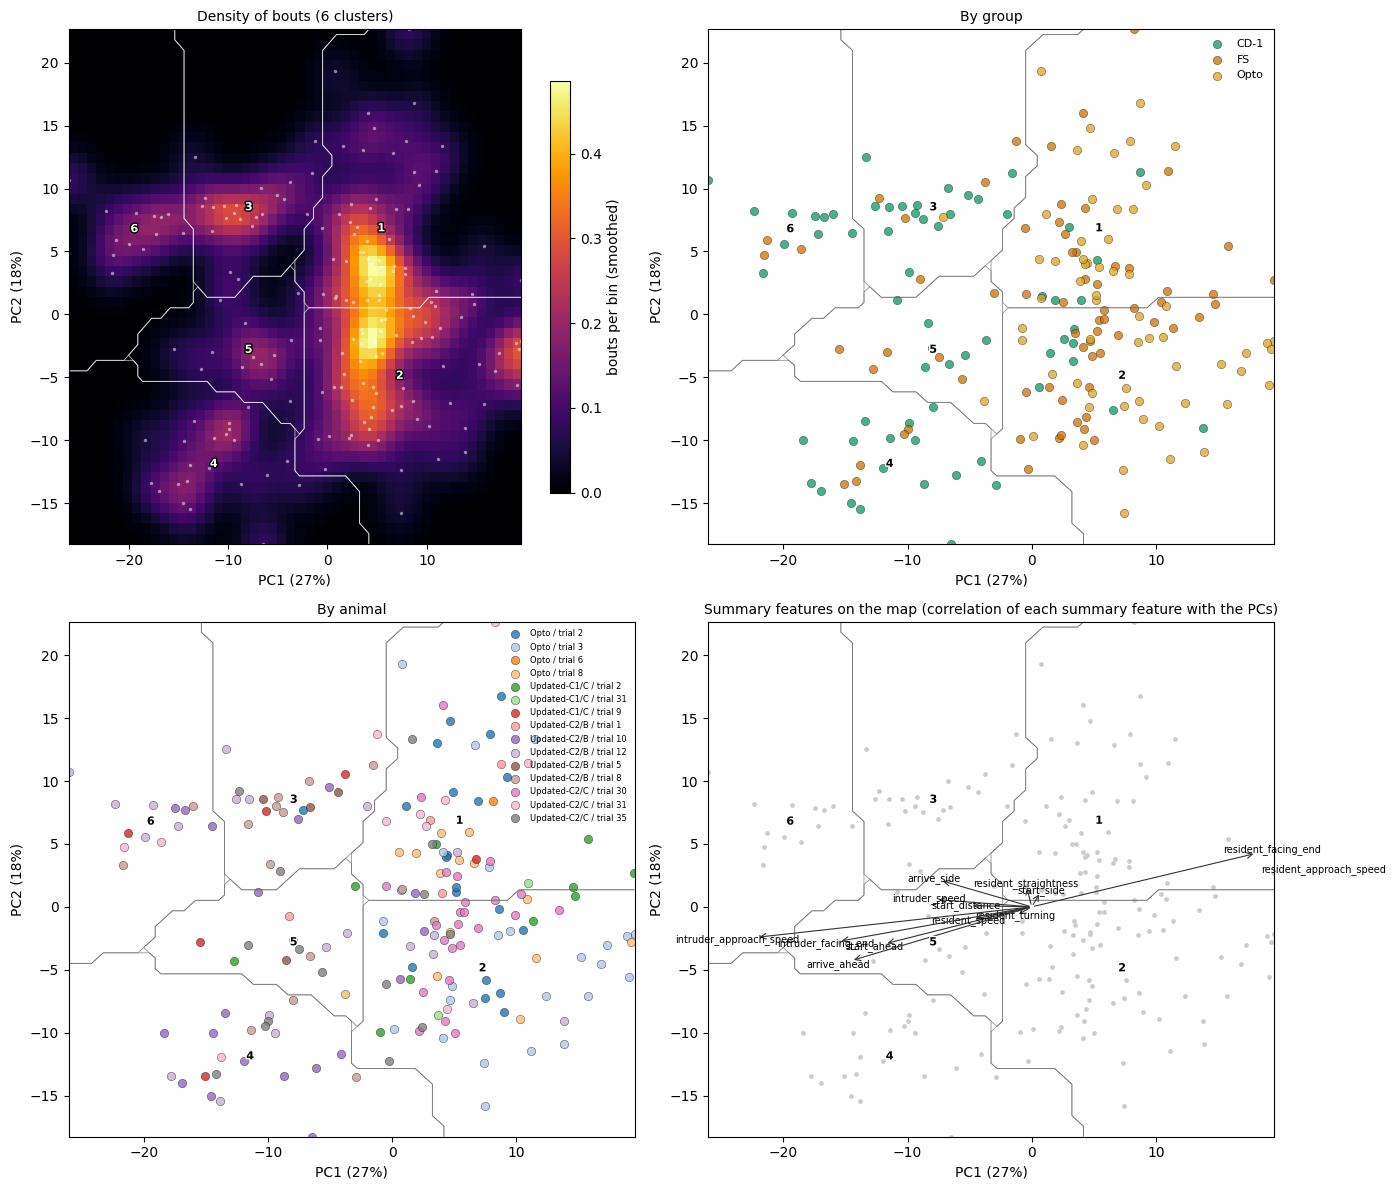

In [16]:
# --- cluster settings: change these and re-run from this cell down ---
# The two feature sets give differently shaped maps, so each has its own settings. The path map
# is a tight core plus a few far-out bouts: it needs less smoothing, or the core is one cluster.
CLUSTER_SETTINGS = {
    #            bins (grid), gaussian_stddev (smoothing, in bins), num_clusters (maximum), compactness
    "summary": WatershedConfig(bins=100, gaussian_stddev=2.0, num_clusters=6, compactness=0.001, mask_empty_bins=False),
    "path":    WatershedConfig(bins=100, gaussian_stddev=2, num_clusters=8, compactness=0.01, mask_empty_bins=False),
    "kinematics": WatershedConfig(bins=50, gaussian_stddev=2.0, num_clusters=6, compactness=0.001, mask_empty_bins=False),   # not tuned yet
}
CLUSTERS = CLUSTER_SETTINGS[FEATURES]

embedding = pc_scores[:, :2]                      # the map being clustered: PC1 and PC2
clusters, centers, hx, hy = run_watershed(embedding, CLUSTERS)
bouts["cluster"] = assign_point_clusters(embedding, clusters, hx, hy, CLUSTERS.bins)
cluster_ids = np.unique(bouts["cluster"])
print(f"asked for up to {CLUSTERS.num_clusters} clusters, got {len(cluster_ids)} with bouts in them: "
      + ", ".join(f"{c} (n={n})" for c, n in bouts["cluster"].value_counts().sort_index().items()))


def finish_panel(ax, title, outline_color="0.4", text_color="black", text_outline="white"):
    draw_cluster_outlines(ax, clusters, hx, hy, color=outline_color)
    label_cluster_centroids(ax, embedding, bouts["cluster"].to_numpy(), text_color=text_color, outline_color=text_outline)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f"PC1 ({explained[0]:.0%})"); ax.set_ylabel(f"PC2 ({explained[1]:.0%})")


fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# density of all bouts: the smoothed histogram that the watershed cuts into clusters
ax = axes[0, 0]
histogram, _, _ = np.histogram2d(embedding[:, 0], embedding[:, 1], bins=[hx, hy])
density = gaussian_filter(histogram, CLUSTERS.gaussian_stddev)
im = ax.imshow(density.T, origin="lower", extent=[hx[0], hx[-1], hy[0], hy[-1]], aspect="auto", cmap="inferno")
plt.colorbar(im, ax=ax, shrink=0.8, label="bouts per bin (smoothed)")
ax.scatter(embedding[:, 0], embedding[:, 1], s=6, color="white", alpha=0.5, linewidths=0)
finish_panel(ax, f"Density of bouts ({len(cluster_ids)} clusters)", outline_color="white", text_color="white", text_outline="black")

ax = axes[0, 1]
for group, color in GROUP_COLORS.items():
    mask = (bouts["group"] == group).to_numpy()
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=36, color=color, alpha=0.75, edgecolor="k", linewidth=0.3,
               label=GROUP_LABELS.get(group, group))
ax.legend(fontsize=8, frameon=False)
finish_panel(ax, "By group")

ax = axes[1, 0]
for k, animal in enumerate(sorted(bouts["animal"].unique())):
    mask = (bouts["animal"] == animal).to_numpy()
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=36, color=plt.cm.tab20(k % 20), alpha=0.8, edgecolor="k",
               linewidth=0.3, label=animal)
ax.legend(fontsize=6, frameon=False)
finish_panel(ax, "By animal")

# the directions of the features, to read what each region of the map means
ax = axes[1, 1]
ax.scatter(embedding[:, 0], embedding[:, 1], s=12, color="0.8", linewidths=0)
scale = 0.85 * np.abs(embedding).max() / np.abs(arrow_table.iloc[:, :2].to_numpy()).max()
for name, row in arrow_table.iterrows():
    ax.annotate("", xy=(row.iloc[0] * scale, row.iloc[1] * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="0.2", linewidth=0.8))
    ax.text(row.iloc[0] * scale * 1.07, row.iloc[1] * scale * 1.07, name, fontsize=7, ha="center", va="center")
finish_panel(ax, f"Summary features on the map ({ARROW_NOTE})")

plt.tight_layout()
plt.show()

### Each group's density with the clusters, and its share of bouts per cluster

Bars: the proportion of each group's bouts that fall in each cluster (each group's bars sum to 1). Dots: the same proportion for each animal with enough bouts. A tall bar with widely scattered dots is driven by one animal.

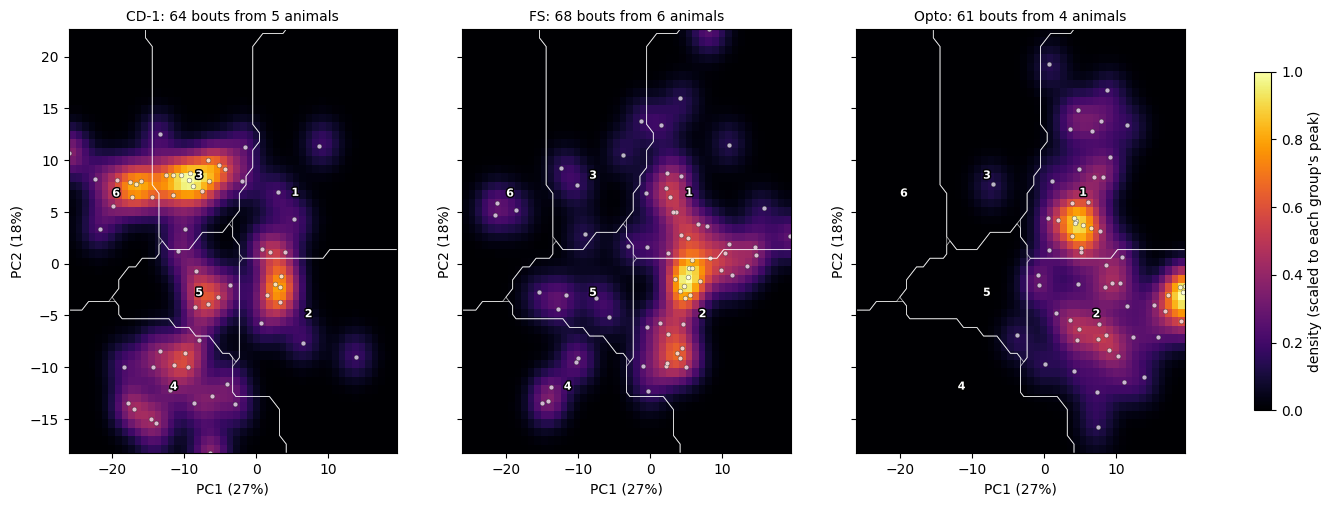

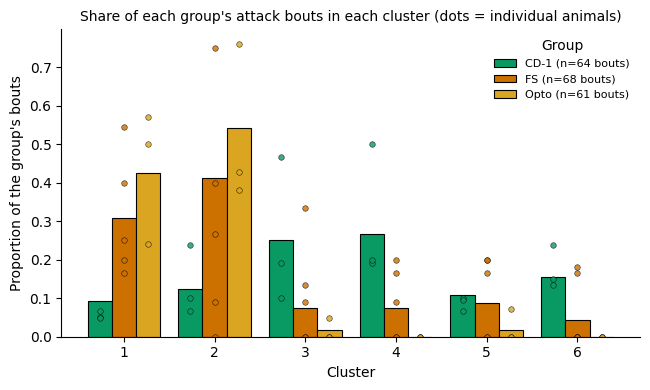

bouts per cluster and group:
group    CD-1  FS  Opto
cluster                
1           6  21    26
2           8  28    33
3          16   5     1
4          17   5     0
5           7   6     1
6          10   3     0

bouts per animal and cluster:
cluster                   1   2  3   4  5  6
animal                                      
Opto / trial 2           12   8  1   0  0  0
Opto / trial 3            6  19  0   0  0  0
Opto / trial 6            1   0  0   0  0  0
Opto / trial 8            7   6  0   0  1  0
Updated-C1/C / trial 2    4   4  0   0  2  0
Updated-C1/C / trial 31   1   1  0   0  0  0
Updated-C1/C / trial 9    1   0  2   1  1  1
Updated-C2/B / trial 1    3   0  0   0  1  0
Updated-C2/B / trial 10   1   2  2  10  2  3
Updated-C2/B / trial 12   1   5  4   4  2  5
Updated-C2/B / trial 5    0   0  3   0  1  0
Updated-C2/B / trial 8    1   1  7   3  1  2
Updated-C2/C / trial 30   6  18  0   0  0  0
Updated-C2/C / trial 31   6   1  1   1  0  2
Updated-C2/C / trial 35   3 

In [17]:
group_order = [g for g in GROUP_COLORS if g in bouts["group"].unique()]

fig, axes = plt.subplots(1, len(group_order), figsize=(6 * len(group_order), 5.5), sharex=True, sharey=True, squeeze=False)
for ax, group in zip(axes[0], group_order):
    in_group = (bouts["group"] == group).to_numpy()
    histogram, _, _ = np.histogram2d(embedding[in_group, 0], embedding[in_group, 1], bins=[hx, hy])
    density = gaussian_filter(histogram, CLUSTERS.gaussian_stddev)
    im = ax.imshow((density / density.max()).T, origin="lower", extent=[hx[0], hx[-1], hy[0], hy[-1]],
                   aspect="auto", cmap="inferno", vmin=0, vmax=1)
    ax.scatter(embedding[in_group, 0], embedding[in_group, 1], s=12, color="white", alpha=0.7, edgecolor="k", linewidth=0.3)
    finish_panel(ax, f"{GROUP_LABELS.get(group, group)}: {in_group.sum()} bouts from "
                     f"{bouts.loc[in_group, 'animal'].nunique()} animals",
                 outline_color="white", text_color="white", text_outline="black")
fig.colorbar(im, ax=axes, shrink=0.8, label="density (scaled to each group's peak)")
plt.show()

# share of each group's bouts in each cluster
BAR_SAVE_PATH = f"figures/pca_{FEATURES}_cluster_share_by_group.png"   # set to None to skip saving

counts = pd.crosstab(bouts["cluster"], bouts["group"]).reindex(index=cluster_ids, columns=group_order, fill_value=0)
shares = counts / counts.sum(axis=0)

fig, ax = plt.subplots(figsize=(max(6, 1.1 * len(cluster_ids)), 4))
bar_width = 0.8 / len(group_order)
for k, group in enumerate(group_order):
    x = np.arange(len(cluster_ids)) + (k - (len(group_order) - 1) / 2) * bar_width
    ax.bar(x, shares[group].to_numpy(), width=bar_width, color=GROUP_COLORS[group], edgecolor="k", linewidth=0.8,
           label=f"{GROUP_LABELS.get(group, group)} (n={counts[group].sum()} bouts)")
    in_group = bouts[bouts["group"] == group]
    animal_counts = pd.crosstab(in_group["animal"], in_group["cluster"]).reindex(columns=cluster_ids, fill_value=0)
    animal_counts = animal_counts[animal_counts.sum(axis=1) >= MIN_ANIMAL_BOUTS]
    for _, row in animal_counts.div(animal_counts.sum(axis=1), axis=0).iterrows():
        ax.plot(x, row.to_numpy(), "o", color=GROUP_COLORS[group], markeredgecolor="k", markeredgewidth=0.4,
                markersize=4, alpha=0.8)
ax.set_xticks(np.arange(len(cluster_ids))); ax.set_xticklabels(cluster_ids)
ax.set_xlabel("Cluster"); ax.set_ylabel("Proportion of the group's bouts")
ax.set_title("Share of each group's attack bouts in each cluster (dots = individual animals)", fontsize=10)
ax.legend(title="Group", frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
if BAR_SAVE_PATH:
    plt.savefig(BAR_SAVE_PATH, dpi=300)
plt.show()

print("bouts per cluster and group:")
print(counts.rename(columns=GROUP_LABELS).to_string())
print("\nbouts per animal and cluster:")
print(pd.crosstab(bouts["animal"], bouts["cluster"]).to_string())

### What each cluster is: feature profile and paths

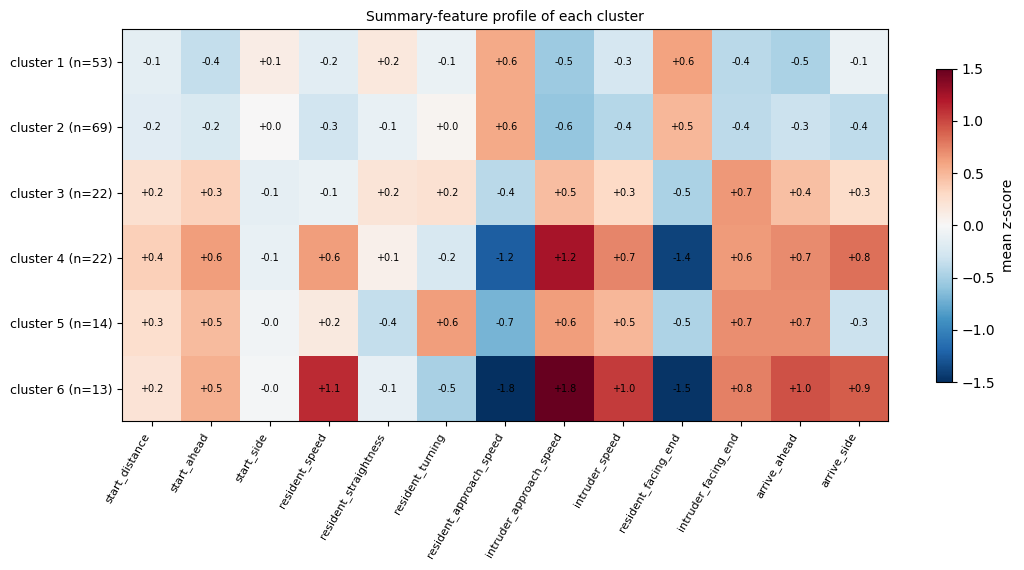

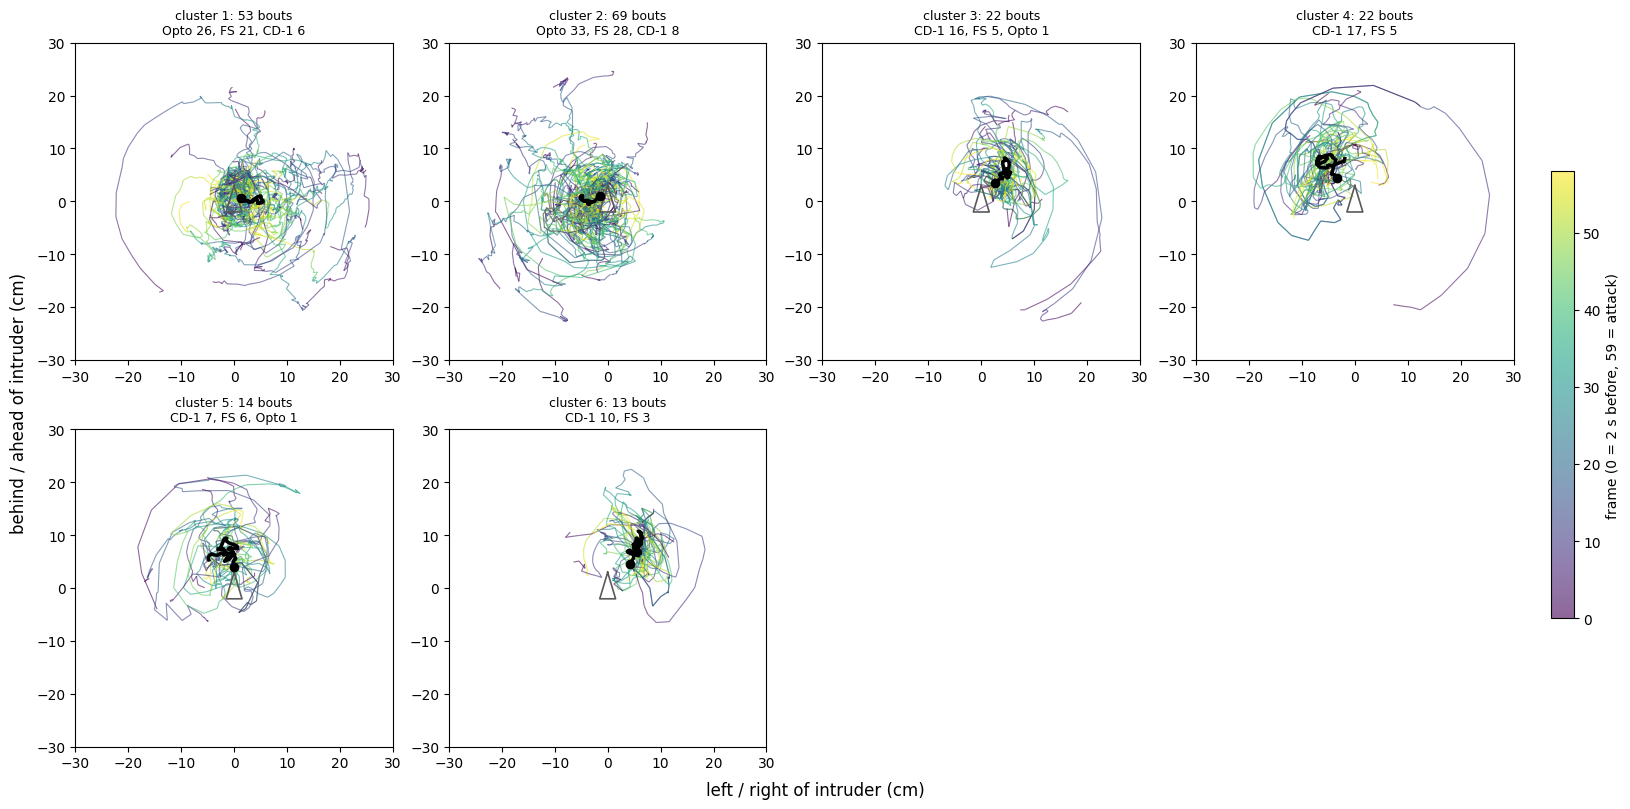

saved 193 bouts to /Users/amonast/Desktop/miniscope/data/attack_bouts/pca_kinematics_watershed_clusters.csv


In [18]:
# mean z-score of every feature in every cluster: red = higher than the average bout, blue = lower
profile = scaled.groupby(bouts["cluster"].to_numpy()).mean()
fig, ax = plt.subplots(figsize=(11, 0.6 * len(cluster_ids) + 2.2))
im = ax.imshow(profile, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(profile.shape[1])); ax.set_xticklabels(profile.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cluster_ids)))
ax.set_yticklabels([f"cluster {c} (n={(bouts['cluster'] == c).sum()})" for c in cluster_ids], fontsize=9)
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        ax.text(j, i, f"{profile.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8, label="mean z-score")
ax.set_title("Summary-feature profile of each cluster", fontsize=10)
plt.tight_layout()
plt.show()

# every path of each cluster (colored by time: dark = 2 s before, bright = attack) with the mean in black
limit = np.ceil(np.abs(paths).max() / 5) * 5
n_frames = paths.shape[1]
n_cols = min(4, len(cluster_ids)); n_rows = int(np.ceil(len(cluster_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.8 * n_cols + 1, 4 * n_rows), squeeze=False, layout="constrained")
for ax, c in zip(axes.flat, cluster_ids):
    members = (bouts["cluster"] == c).to_numpy()
    cluster_paths = paths[members]
    segments = np.stack([cluster_paths[:, :-1], cluster_paths[:, 1:]], axis=2).reshape(-1, 2, 2)
    lc = LineCollection(segments, cmap="viridis", linewidth=0.8, alpha=0.6)
    lc.set_array(np.tile(np.arange(n_frames - 1), len(cluster_paths))); lc.set_clim(0, n_frames - 2)
    ax.add_collection(lc)
    mean_path = cluster_paths.mean(axis=0)
    ax.plot(mean_path[:, 0], mean_path[:, 1], color="k", linewidth=2.5, zorder=4)
    ax.plot(mean_path[-1, 0], mean_path[-1, 1], "o", color="k", markersize=6, zorder=5)
    ax.plot([0, -1.5, 1.5, 0], [3, -2, -2, 3], color="0.35", linewidth=1.2, zorder=3)   # intruder, facing up
    ax.set_xlim(-limit, limit); ax.set_ylim(-limit, limit); ax.set_aspect("equal")
    by_group = bouts.loc[members, "group"].map(GROUP_LABELS).value_counts()
    ax.set_title(f"cluster {c}: {members.sum()} bouts\n" + ", ".join(f"{g} {n}" for g, n in by_group.items()), fontsize=9)
for ax in axes.flat[len(cluster_ids):]:
    ax.axis("off")
fig.colorbar(lc, ax=axes, shrink=0.6, pad=0.02, label="frame (0 = 2 s before, 59 = attack)")
fig.supxlabel("left / right of intruder (cm)"); fig.supylabel("behind / ahead of intruder (cm)")
plt.show()

out = bouts[["bout_id", "group", "group_folder", "trial", "trial_number", "animal", "cluster"]].copy()
out["PC1"], out["PC2"] = embedding[:, 0], embedding[:, 1]
out.to_csv(BOUTS_DIR / f"pca_{FEATURES}_watershed_clusters.csv", index=False)
print(f"saved {len(out)} bouts to {BOUTS_DIR / f'pca_{FEATURES}_watershed_clusters.csv'}")